# 🌊 Projekt: Klasifikace mořských živočichů — Milestone 1

**Dataset:** [Sea Animals Image Dataset](https://www.kaggle.com/datasets/vencerlanz09/sea-animals-image-dataste) (Kaggle)
**Úloha:** klasifikace obrázků do více tříd (multi-class image classification)

### Plán notebooku
| Část | Obsah |
|---|---|
| **0 — Průzkum dat (EDA)** | stažení, struktura, počty tříd, rozměry, poškozené soubory, duplikáty |
| 1 — Dataset & DataLoader | split, vlastní `Dataset`, transformace, vizualizace batche |
| 2 — Baseline CNN | jednoduchá CNN od nuly |
| 3 — Tréninková smyčka | ruční train/val loop, metriky |
| 4 — Overfit sanity check | 16 vzorků → loss ≈ 0, accuracy 100 % |
| 5 — Vylepšený model | silnější augmentace, BatchNorm, GAP, AdamW, váhy tříd |
| 6 — Shrnutí | výsledky baseline a vylepšeného modelu, vyhodnocení na testu |

> Notebook obsahuje **Části 0–6** — kompletní Milestone 1.
>
> 🖥️ Notebook běží **lokálně** (Windows, GPU GTX 1080) v prostředí `.venv` (PyTorch 2.14 + CUDA 12.6).

# 📌 Část 0 — Průzkum dat (EDA)

**Proč to děláme:** dřív než napíšeme `Dataset`, musíme vědět, *co* v datech je.
Konkrétně hledáme věci, které by později tiše rozbily pipeline:

- 🗂️ **Struktura složek** — jak jsou obrázky uložené a jak z nich získat label.
- ⚖️ **Nevyváženost tříd** — pokud má jedna třída 10× víc obrázků, accuracy může být zavádějící.
- 📐 **Rozměry a formáty** — různé velikosti ⇒ potřebujeme `Resize`; jiný počet kanálů (RGBA, grayscale) ⇒ potřebujeme `.convert("RGB")`, jinak `DataLoader` nepůjde poskládat do batche.
- 💥 **Poškozené soubory** — jeden nečitelný obrázek shodí celý trénink uprostřed epochy.
- 👯 **Duplikáty** — stejný obrázek v train i val = únik dat (*data leakage*) a nadhodnocená validace.

## ⚙️ Nastavení prostředí

Notebook spouštíme **lokálně** ve virtuálním prostředí `.venv` (ve VS Code vybrat kernel `.venv` vpravo nahoře).

| Komponenta | Verze / poznámka |
|---|---|
| GPU | NVIDIA GTX 1080 (8 GB, architektura Pascal) |
| PyTorch | `torch 2.14.0+cu126`, `torchvision 0.29.0+cu126` — poslední verze s podporou Pascal GPU (CUDA 12.6 wheely) |
| CPU | 6 jader ⇒ důležité pro `num_workers` v `DataLoader`u |

Instalace PyTorch (jednorázově, mimo notebook):
```
pip install torch==2.14.0 torchvision==0.29.0 --index-url https://download.pytorch.org/whl/cu126
```

Ostatní knihovny instaluje buňka níže. `%pip` (na rozdíl od `!pip`) instaluje **do prostředí běžícího kernelu**,
takže se balíčky nemůžou omylem nainstalovat do jiného Pythonu.

In [1]:
# pip-system-certs: Python začne používat certifikáty z Windows (potřeba kvůli antiviru Avast, viz níže)
%pip install -q kagglehub pandas matplotlib seaborn scikit-learn pip-system-certs

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch

sns.set_theme(style="whitegrid")

SEED = 42                      # pevný seed => výsledky půjdou zopakovat
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True   # GPU: jen deterministické algoritmy => stejné výsledky při každém běhu
torch.backends.cudnn.benchmark = False      # nevybírat nejrychlejší (ale náhodně se lišící) algoritmus

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch version: 2.14.0+cu126
device: cuda
GPU: NVIDIA GeForce GTX 1080


<!-- ## 📥 Stažení datasetu

Dataset držíme **přímo ve složce projektu** v `data/sea_animals/` (jedna podsložka = jedna třída), aby bylo vše na jednom místě.

- Pokud složka už obsahuje data, **nic se nestahuje**.
- Jinak ho knihovna **`kagglehub`** stáhne parametrem `output_dir` rovnou do této složky (bez něj by ho uložila
  do skryté cache `~/.cache/kagglehub/...`).

Cesty používáme **relativní** (vůči složce s notebookem), takže projekt funguje i po přesunu nebo na jiném počítači.

> ⚠️ **Chyba `SSL: CERTIFICATE_VERIFY_FAILED`:** antivirus (u nás Avast) kontroluje HTTPS provoz a podepisuje
> spojení vlastním certifikátem. Windows mu věří, ale Python má vlastní seznam certifikátů, kde Avast není.
> Řešení je balíček `pip-system-certs` (instalovaný výše), díky kterému Python použije certifikáty z Windows.
> Po jeho instalaci je potřeba **restartovat kernel**. -->

In [3]:
import kagglehub

DATA_ROOT = Path("data") / "sea_animals"     # relativní cesta vůči složce notebooku

if DATA_ROOT.exists() and any(DATA_ROOT.iterdir()):
    print("Dataset už je ve složce projektu:", DATA_ROOT)
else:
    kagglehub.dataset_download("vencerlanz09/sea-animals-image-dataste", output_dir=str(DATA_ROOT))
    print("Dataset stažen do:", DATA_ROOT)

Dataset už je ve složce projektu: data\sea_animals


E:\Ondra_Local\Projects\Vsb\ML\project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 🗂️ Struktura složek

Podíváme se, jak dataset vypadá na disku. Očekáváme formát „**jedna složka = jedna třída**“
(např. `Jelly Fish/xxx.jpg`). Pak je label prostě **název nadřazené složky**.

In [4]:
def print_tree(root, max_depth=2, max_items=6, _depth=0):
    # Vypíše strom složek do hloubky max_depth (ukáže jen pár položek na úroveň).
    if _depth > max_depth:
        return
    items = sorted(Path(root).iterdir())
    for p in items[:max_items]:
        n_files = len(list(p.iterdir())) if p.is_dir() else None
        info = f"  ({n_files} položek)" if p.is_dir() else ""
        print("    " * _depth + ("📁 " if p.is_dir() else "📄 ") + p.name + info)
        if p.is_dir():
            print_tree(p, max_depth, max_items, _depth + 1)
    if len(items) > max_items:
        print("    " * _depth + f"... a dalších {len(items) - max_items}")

print_tree(DATA_ROOT, max_depth=1)

📁 Clams  (497 položek)
    📄 10004815975_14842bfd9d_o.jpg
    📄 10057431354_be4b6d0629_o.jpg
    📄 10057493504_42562b0f7a_o.jpg
    📄 10057511635_2ea008d261_o.jpg
    📄 10057638633_a1200f54cd_o.jpg
    📄 10065810835_7424c06b4b_o.jpg
    ... a dalších 491
📁 Corals  (500 položek)
    📄 10465606544_52913a3632_o.jpg
    📄 10465800323_cb0dec6996_o.jpg
    📄 10466334974_85c531844d_o.jpg
    📄 10466516113_b28dbc5d17_o.jpg
    📄 10694747335_e048ab5dc4_o.jpg
    📄 10712079_196e275866_o.jpg
    ... a dalších 494
📁 Crabs  (499 položek)
    📄 10010837894_757b671eef_o.jpg
    📄 10089623855_55cdbc096e_o.jpg
    📄 10130978923_aedfab2942_b.jpg
    📄 10156107473_caeb9e518a_o.jpg
    📄 102513929_3bb9b81383_o.jpg
    📄 10308895593_5cb14a143c_o.jpg
    ... a dalších 493
📁 Dolphin  (782 položek)
    📄 10004986625_0f786ab86b_b.jpg
    📄 10024981276_65f3d41599_b.jpg
    📄 10080987554_27d23b7ca3_o.jpg
    📄 10132691013_8d9e263177_o.jpg
    📄 10153182025_b69bef91f0_b.jpg
    📄 10162596245_7b2714189c_b.jpg
    

## 📋 Index všech obrázků

Projdeme rekurzivně všechny soubory s koncovkou obrázku a uložíme si je do tabulky
(`pandas.DataFrame`) se sloupci `path` a `label`.

**Proč tabulka:** stejný seznam použijeme v Části 1 pro **stratifikovaný split** a jako vstup
do našeho vlastního `Dataset`u. Tím, že label bereme z názvu složky (a ne ručně), vyloučíme
chybu typu „obrázek medúzy má label žraloka“.

In [5]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

all_files = [p for p in DATA_ROOT.rglob("*") if p.is_file()]
img_files = [p for p in all_files if p.suffix.lower() in IMG_EXTS]

# Soubory, které nejsou obrázky (README, csv...) jen vypíšeme, ať víme, že existují.
other_ext = Counter(p.suffix.lower() for p in all_files if p.suffix.lower() not in IMG_EXTS)
print("Všech souborů:", len(all_files))
print("Obrázků:", len(img_files))
print("Ostatní přípony:", dict(other_ext) if other_ext else "žádné")

df = pd.DataFrame({
    "path":  [p.as_posix() for p in img_files],   # lomítka "/" fungují na Windows i Linuxu
    "label": [p.parent.name for p in img_files],   # label = název složky
    "ext":   [p.suffix.lower() for p in img_files],
})
df.head()

Všech souborů: 13711
Obrázků: 13711
Ostatní přípony: žádné


,path,label,ext
0,data/sea_animals/Clams/10004815975_14842bfd9d_...,Clams,.jpg
1,data/sea_animals/Clams/10057431354_be4b6d0629_...,Clams,.jpg
2,data/sea_animals/Clams/10057493504_42562b0f7a_...,Clams,.jpg
3,data/sea_animals/Clams/10057511635_2ea008d261_...,Clams,.jpg
4,data/sea_animals/Clams/10057638633_a1200f54cd_...,Clams,.jpg


## ⚖️ Rozložení tříd

Kolik tříd máme a kolik obrázků má každá z nich? Tohle rozhodne:
- počet výstupních neuronů modelu (`n_classes`),
- jestli stačí obyčejná accuracy, nebo se budeme dívat i na metriky po třídách,
- že split musí být **stratifikovaný**.

Počet tříd: 23
Nejvíc obrázků : Turtle_Tortoise -> 1903
Nejméně obrázků: Seal -> 414
Poměr nevyváženosti (max/min): 4.6x
Accuracy, kdyby model tipoval vždy nejčastější třídu: 13.9%


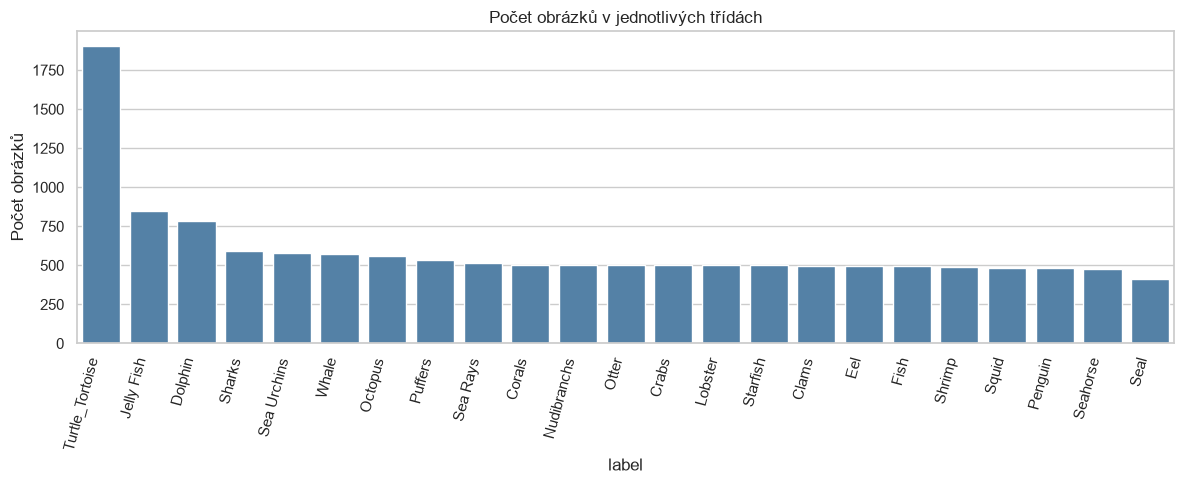

In [6]:
class_counts = df["label"].value_counts().sort_values(ascending=False)
class_names = sorted(class_counts.index)          # abecední pořadí = pevné mapování na indexy
n_classes = len(class_names)

print("Počet tříd:", n_classes)
print("Nejvíc obrázků :", class_counts.index[0],  "->", class_counts.iloc[0])
print("Nejméně obrázků:", class_counts.index[-1], "->", class_counts.iloc[-1])
print(f"Poměr nevyváženosti (max/min): {class_counts.iloc[0] / class_counts.iloc[-1]:.1f}x")
print(f"Accuracy, kdyby model tipoval vždy nejčastější třídu: {class_counts.iloc[0] / len(df):.1%}")

plt.figure(figsize=(12, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.xticks(rotation=75, ha="right")
plt.ylabel("Počet obrázků")
plt.title("Počet obrázků v jednotlivých třídách")
plt.tight_layout(); plt.show()

> 💡 **Proč počítáme „accuracy nejčastější třídy“:** je to nejhloupější možný model
> (vždy řekne stejnou třídu). Náš baseline musí být **výrazně lepší** než tohle číslo,
> jinak se nic nenaučil. A při náhodném tipování je accuracy jen `1 / n_classes`.

## 🔎 Ukázka obrázků z každé třídy

Vizuální kontrola: sedí obrázky ke svým labelům? Nejsou tam nesmysly (loga, text, prázdné obrázky)?

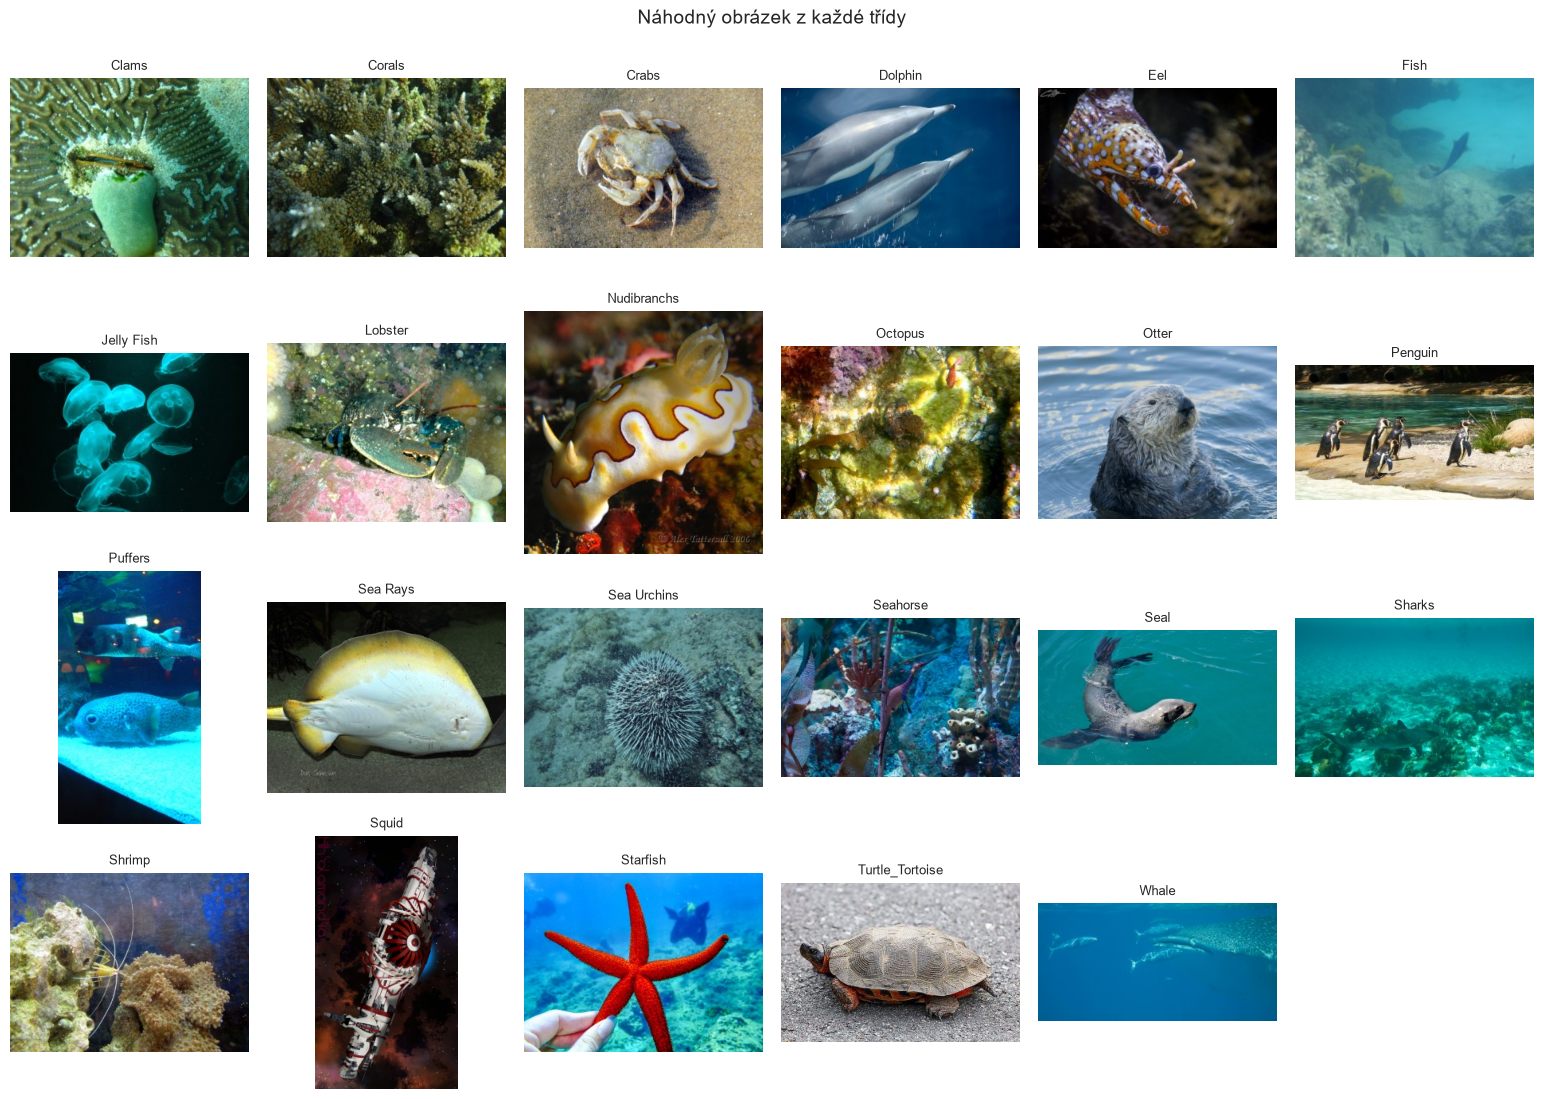

In [7]:
rng = np.random.default_rng(SEED)
n_cols = 6
n_rows = int(np.ceil(n_classes / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.6, n_rows * 2.8))
for ax in axes.ravel():
    ax.axis("off")
for ax, cls in zip(axes.ravel(), class_names):
    sample_path = rng.choice(df.loc[df["label"] == cls, "path"].values)
    ax.imshow(Image.open(sample_path).convert("RGB"))
    ax.set_title(cls, fontsize=9)
plt.suptitle("Náhodný obrázek z každé třídy", fontsize=14)
plt.tight_layout(); plt.show()

## 📐 Rozměry, barevné módy a poškozené soubory

Pro každý obrázek zjistíme šířku, výšku a **mód** (`RGB`, `RGBA`, `L` = grayscale, `P` = paleta…).
Zároveň zkusíme obrázek **opravdu dekódovat** — pokud to selže, soubor je poškozený.

- `Image.open()` je „líné“ — přečte jen hlavičku, proto je rychlé.
- `img.load()` načte skutečná pixelová data, teprve tady se poškozený soubor projeví.

Projdeme **všechny** obrázky (trvá to cca 1–2 minuty), protože poškozený může být klidně jen jeden.

In [8]:
def inspect_image(path):
    # Vrátí (šířka, výška, mód, chyba). Při chybě vrátí None + text chyby.
    try:
        with Image.open(path) as img:
            img.load()                       # vynutí dekódování pixelů
            return img.width, img.height, img.mode, None
    except Exception as e:
        return None, None, None, f"{type(e).__name__}: {e}"

results = [inspect_image(p) for p in df["path"]]
df["width"], df["height"], df["mode"], df["error"] = zip(*results)

broken = df[df["error"].notna()]
print("Poškozených souborů:", len(broken))
if len(broken):
    display(broken[["path", "label", "error"]])

Poškozených souborů: 0


In [9]:
ok = df[df["error"].isna()].copy()

print("Barevné módy:")
print(ok["mode"].value_counts().to_string())
print("\nFormáty souborů:")
print(ok["ext"].value_counts().to_string())
print("\nStatistika rozměrů (px):")
print(ok[["width", "height"]].describe().round(0).to_string())

Barevné módy:
mode
RGB     13687
RGBA       22
L           2

Formáty souborů:
ext
.jpg    13666
.png       45

Statistika rozměrů (px):
         width   height
count  13711.0  13711.0
mean     293.0    222.0
std       55.0     50.0
min      131.0     63.0
25%      300.0    200.0
50%      300.0    218.0
75%      300.0    225.0
max     5120.0   3840.0


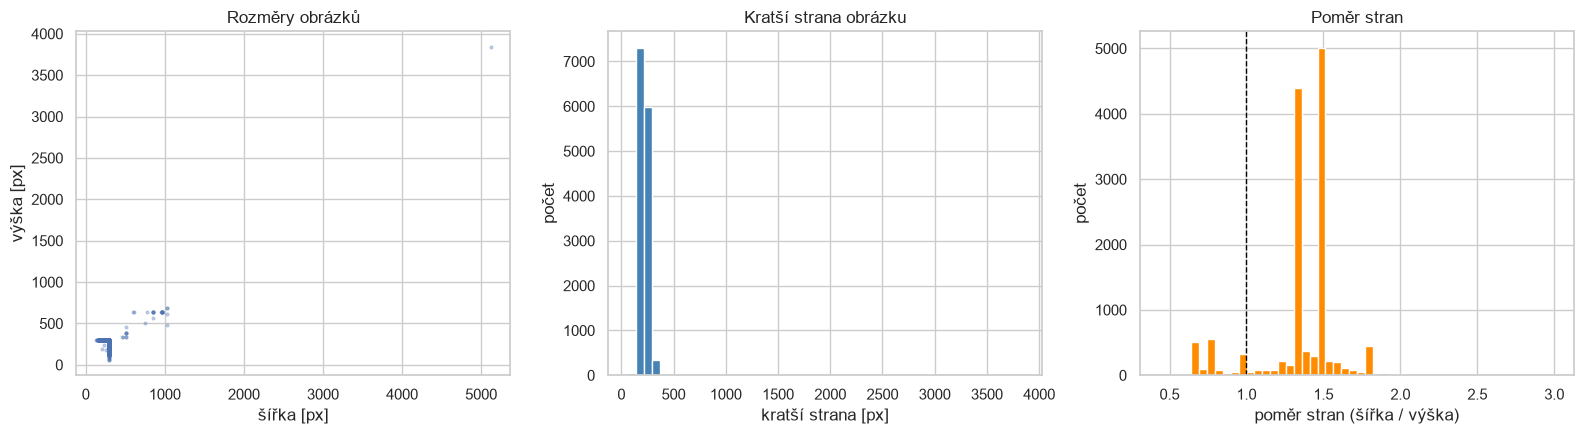

Obrázků s kratší stranou < 128 px: 23 (0.2%)


In [10]:
ok["aspect"] = ok["width"] / ok["height"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(ok["width"], ok["height"], s=4, alpha=0.3)
axes[0].set_xlabel("šířka [px]"); axes[0].set_ylabel("výška [px]")
axes[0].set_title("Rozměry obrázků")

axes[1].hist(np.minimum(ok["width"], ok["height"]), bins=50, color="steelblue")
axes[1].set_xlabel("kratší strana [px]"); axes[1].set_ylabel("počet")
axes[1].set_title("Kratší strana obrázku")

axes[2].hist(ok["aspect"].clip(0.3, 3), bins=50, color="darkorange")
axes[2].axvline(1.0, color="black", ls="--", lw=1)
axes[2].set_xlabel("poměr stran (šířka / výška)"); axes[2].set_ylabel("počet")
axes[2].set_title("Poměr stran")

plt.tight_layout(); plt.show()

small = (np.minimum(ok["width"], ok["height"]) < 128).sum()
print(f"Obrázků s kratší stranou < 128 px: {small} ({small / len(ok):.1%})")

> 💡 **Co z toho plyne pro transformace:**
> - Obrázky mají různé rozměry ⇒ všechny musíme převést na **stejnou velikost** (`Resize`),
>   jinak je `DataLoader` nedokáže složit do jednoho tenzoru `(B, C, H, W)`.
> - Pokud se objeví jiné módy než `RGB` ⇒ v `__getitem__` použijeme `.convert("RGB")`,
>   aby měl každý obrázek přesně **3 kanály**.
> - Kratší strana většiny obrázků nám říká, jak velké rozlišení si můžeme dovolit,
>   aniž bychom obrázky výrazně zvětšovali (to by nepřidalo informaci, jen výpočetní čas).

## 👯 Duplikáty

Spočítáme **MD5 hash** obsahu každého souboru. Dva soubory se stejným hashem jsou
bajt po bajtu identické.

**Proč to řešíme:** kdyby stejný obrázek skončil jednou v trénovací a jednou ve validační
sadě, model by ho „znal“ a validační accuracy by byla falešně vyšší. Ještě horší je, když
je stejný obrázek ve **dvou různých třídách** — pak má protichůdné labely.

In [11]:
def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

ok["md5"] = [file_md5(p) for p in ok["path"]]

dup_groups = ok.groupby("md5").filter(lambda g: len(g) > 1)
n_extra = len(dup_groups) - dup_groups["md5"].nunique()   # kolik souborů je „navíc“
print("Skupin duplikátů:", dup_groups["md5"].nunique())
print("Nadbytečných kopií (k odstranění):", n_extra)

# Duplikáty, které mají v různých složkách RŮZNÉ labely
conflicts = dup_groups.groupby("md5")["label"].nunique()
conflicts = conflicts[conflicts > 1]
print("Duplikátů s konfliktními labely:", len(conflicts))
if len(conflicts):
    display(dup_groups[dup_groups["md5"].isin(conflicts.index)]
            .sort_values("md5")[["md5", "label", "path"]].head(20))

Skupin duplikátů: 58
Nadbytečných kopií (k odstranění): 75
Duplikátů s konfliktními labely: 42


,md5,label,path
13300,0195f86905fac06777a591b62463fb40,Whale,data/sea_animals/Whale/29853353308_2c91520e29_...
9338,0195f86905fac06777a591b62463fb40,Sharks,data/sea_animals/Sharks/29853353308_2c91520e29...
13642,029a7f938b02a1f9b32c07ec6957192e,Whale,data/sea_animals/Whale/Whale (21).jpg
2131,029a7f938b02a1f9b32c07ec6957192e,Dolphin,data/sea_animals/Dolphin/Dolphin (219).jpg
13397,05beaedc38be9920aace1598026f5f3a,Whale,data/sea_animals/Whale/43007890704_59e7f44985_...
9446,05beaedc38be9920aace1598026f5f3a,Sharks,data/sea_animals/Sharks/43007890704_59e7f44985...
13707,0734a681e4e395f40944a61789980fd5,Whale,data/sea_animals/Whale/Whale (80).jpg
2071,0734a681e4e395f40944a61789980fd5,Dolphin,data/sea_animals/Dolphin/Dolphin (166).jpg
10600,07faa8a34c1c831a406b34734b92d90a,Squid,data/sea_animals/Squid/5263732245_646f5c2022_b...
5445,07faa8a34c1c831a406b34734b92d90a,Octopus,data/sea_animals/Octopus/5263732245_646f5c2022...


## 🧹 Vyčištění a uložení indexu

Rozhodnutí:
1. **Poškozené soubory vyřadíme** — nejdou načíst, model z nich nic nemá.
2. **Duplikáty s konfliktním labelem vyřadíme úplně** — nevíme, který label je správný.
3. **Ostatní duplikáty** necháme jen v **jedné kopii** — zabráníme tak úniku dat mezi train a val.

Výsledek uložíme do `sea_animals_index.csv`; z něj vyjde Část 1 (split + `Dataset`).

In [12]:
clean = ok[~ok["md5"].isin(conflicts.index)]                 # pravidlo 2
clean = clean.drop_duplicates(subset="md5", keep="first")    # pravidlo 3
clean = clean.reset_index(drop=True)

# Pevné mapování název třídy -> číslo (0 .. n_classes-1), abecedně
class_to_idx = {c: i for i, c in enumerate(sorted(clean["label"].unique()))}
clean["label_idx"] = clean["label"].map(class_to_idx)

print(f"Původně obrázků:      {len(df)}")
print(f"Poškozených:          {len(broken)}")
print(f"Po vyčištění:         {len(clean)}  (odebráno {len(df) - len(clean)})")
print(f"Tříd:                 {len(class_to_idx)}")

clean[["path", "label", "label_idx", "width", "height", "mode"]].to_csv("sea_animals_index.csv", index=False)
print("\nUloženo: sea_animals_index.csv")
class_to_idx

Původně obrázků:      13711
Poškozených:          0
Po vyčištění:         13594  (odebráno 117)
Tříd:                 23

Uloženo: sea_animals_index.csv


{'Clams': 0,
 'Corals': 1,
 'Crabs': 2,
 'Dolphin': 3,
 'Eel': 4,
 'Fish': 5,
 'Jelly Fish': 6,
 'Lobster': 7,
 'Nudibranchs': 8,
 'Octopus': 9,
 'Otter': 10,
 'Penguin': 11,
 'Puffers': 12,
 'Sea Rays': 13,
 'Sea Urchins': 14,
 'Seahorse': 15,
 'Seal': 16,
 'Sharks': 17,
 'Shrimp': 18,
 'Squid': 19,
 'Starfish': 20,
 'Turtle_Tortoise': 21,
 'Whale': 22}

## 📝 Shrnutí Části 0

- **Počet obrázků / tříd:** 13 711 obrázků ve 23 třídách.
- **Nevyváženost:** největší třída *Turtle_Tortoise* (1 903 obr.), nejmenší *Seal* (414 obr.), poměr 4,6×.
  Baseline „vždy nejčastější třída“ má accuracy 13,9 % (náhodné tipování 1/23 ≈ 4,3 %) ⇒ náš model musí být výrazně lepší.
  ⇒ Split v Části 1 uděláme **stratifikovaně**.
- **Rozměry:** obrázky mají různé velikosti (průměrně 293 × 222 px) ⇒ použijeme `Resize` na pevnou velikost.
- **Barevné módy:** v datech jsou 3 různé módy — `RGB` (13 687), `RGBA` (22, PNG s průhledností) a `L` (2, černobílé) ⇒ v `__getitem__` voláme `.convert("RGB")`, aby měl každý vstup přesně 3 kanály.
- **Poškozené soubory:** 0 — nebylo potřeba nic vyřazovat.
- **Duplikáty:** 75 nadbytečných kopií odstraněno; 42 skupin duplikátů mělo konfliktní label (stejný obrázek ve dvou třídách) a byly vyřazeny celé. Zabráníme tím úniku dat mezi train a val a protichůdným labelům.

**Další krok (Část 1):** stratifikovaný train/val/test split, vlastní `Dataset`, transformace a `DataLoader`.

**Výsledek čištění:** z 13 711 obrázků zůstalo **13 594** (odebráno 117) ve 23 třídách.

# 📦 Část 1 — Vlastní Dataset & DataLoader

V hodině jsme použili hotový `datasets.FashionMNIST`. Tady si **celou datovou pipeline napíšeme sami**:

$$\text{tabulka (cesta, label)} \xrightarrow{\text{split}} \text{train / val / test} \xrightarrow{\text{Dataset}} (\text{tenzor}, \text{label}) \xrightarrow{\text{DataLoader}} \text{batch } (B, 3, H, W)$$

Postup:
1. Stratifikovaný **split** na train / val / test.
2. Vlastní třída **`SeaAnimalsDataset`** (`__len__`, `__getitem__`).
3. Spočítání **průměru a směrodatné odchylky** pro normalizaci (jen z trénovacích dat).
4. **Transformace** (`Resize`, augmentace, `ToTensor`, `Normalize`).
5. **`DataLoader`** s batchováním, shufflem a workery.
6. **Vizualizace batche** a kontrola tvarů tenzorů.

In [13]:
import time
from sklearn.model_selection import train_test_split

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE    = 128     # všechny obrázky převedeme na 128 x 128 px
BATCH_SIZE  = 64
NUM_WORKERS = 4       # 6 jader CPU: 4 workery načítají data, zbytek pro hlavní proces a systém

print("CPU jader:", os.cpu_count())

CPU jader: 6


## ✂️ Stratifikovaný split: train / val / test (70 / 15 / 15)

- **train** — na těchto datech se model učí (počítají se z nich gradienty).
- **val** — po každé epoše měříme, jak model funguje na datech, která neviděl. Podle ní ladíme hyperparametry.
- **test** — **schováme si ho až na úplný konec projektu** (pozdější milestony). Kdybychom podle něj cokoli ladili, přestal by být nezávislý.

**Proč stratifikovaně (`stratify=`):** máme nevyvážené třídy (Seal 414 vs. Turtle 1 903).
Při čistě náhodném dělení by se mohlo stát, že malá třída bude ve validaci skoro chybět.
Stratifikace zaručí, že **každá třída má ve všech třech sadách stejný podíl**.

Dělíme ve dvou krocích: nejdřív 70 % train vs. 30 % zbytek, pak zbytek napůl na val a test.
`random_state=SEED` zajistí, že split bude při každém spuštění stejný.

In [14]:
data = clean[["path", "label", "label_idx"]].copy()

train_df, temp_df = train_test_split(
    data, test_size=0.30, stratify=data["label_idx"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label_idx"], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

idx_to_class = {i: c for c, i in class_to_idx.items()}   # číslo -> název (pro výpisy a grafy)
N_CLASSES = len(class_to_idx)

print(f"train: {len(train_df):5d}  ({len(train_df) / len(data):.1%})")
print(f"val:   {len(val_df):5d}  ({len(val_df) / len(data):.1%})")
print(f"test:  {len(test_df):5d}  ({len(test_df) / len(data):.1%})")

# Kontrola: žádný soubor nesmí být ve dvou sadách zároveň (duplikáty jsme odstranili v Části 0)
assert not set(train_df["path"]) & set(val_df["path"])
assert not set(train_df["path"]) & set(test_df["path"])
assert not set(val_df["path"])   & set(test_df["path"])
print("✅ Sady se nepřekrývají.")

train:  9515  (70.0%)
val:    2039  (15.0%)
test:   2040  (15.0%)
✅ Sady se nepřekrývají.


Největší rozdíl v podílu třídy mezi sadami: 0.04%


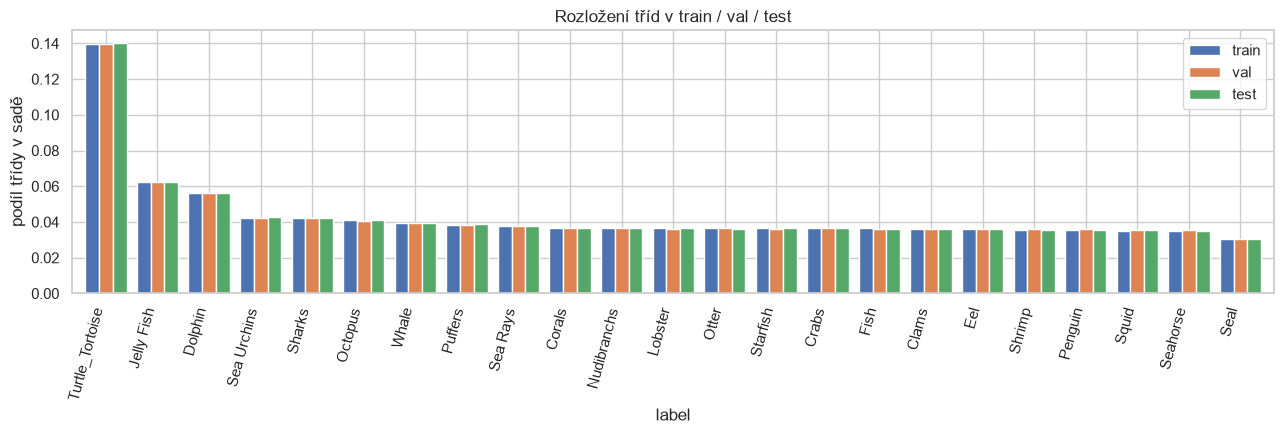

In [15]:
# Ověření stratifikace: podíl každé třídy v jednotlivých sadách by měl být téměř stejný
props = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "val":   val_df["label"].value_counts(normalize=True),
    "test":  test_df["label"].value_counts(normalize=True),
}).sort_values("train", ascending=False)

max_diff = (props[["val", "test"]].sub(props["train"], axis=0)).abs().max().max()
print(f"Největší rozdíl v podílu třídy mezi sadami: {max_diff:.2%}")

props.plot(kind="bar", figsize=(13, 4.5), width=0.8)
plt.ylabel("podíl třídy v sadě"); plt.title("Rozložení tříd v train / val / test")
plt.xticks(rotation=75, ha="right"); plt.tight_layout(); plt.show()

## 🧱 Vlastní `Dataset`

`torch.utils.data.Dataset` je jednoduché „rozhraní“: PyTorch od nás chce jen dvě metody.

| Metoda | Co dělá | Kdo ji volá |
|---|---|---|
| `__len__()` | vrátí počet vzorků | `DataLoader` (aby věděl, kolik je batchů) |
| `__getitem__(idx)` | vrátí **jeden** vzorek `(obrázek, label)` | `DataLoader` pro každý index v batchi |

**Důležitá rozhodnutí:**
- **Obrázky načítáme až v `__getitem__`** (*lazy loading*), ne všechny v `__init__`. 13 700 obrázků
  by se do paměti vešlo jen tak tak; takhle je v paměti vždy jen to, co se právě zpracovává.
- **`.convert("RGB")`** — sjednotí všechny barevné módy z Části 0 na 3 kanály. Bez toho by např. obrázek
  v módu `L` měl tvar `(1, H, W)` a `DataLoader` by batch nedokázal poskládat.
- **Label jako `torch.long`** — `nn.CrossEntropyLoss` vyžaduje celočíselné indexy tříd (ne one-hot, ne float).
- Ukládáme si **obyčejné Python seznamy** místo DataFrame — indexování seznamu je rychlejší a jednodušší.

### ⚠️ Proč je třída v souboru `dataset.py` (Windows + `num_workers`)
Na Windows `DataLoader` s `num_workers > 0` spouští workery jako **úplně nové procesy Pythonu** (metoda *spawn*;
Linux/Colab místo toho proces jen zkopíruje — *fork*). Nový proces si musí třídu `SeaAnimalsDataset`
**naimportovat**. Třídu napsanou přímo v buňce notebooku ale importovat nejde ⇒ worker spadne na
`AttributeError: Can't get attribute 'SeaAnimalsDataset'` a buňka **zamrzne** (ověřeno).

Řešení: magický příkaz **`%%writefile dataset.py`** uloží obsah buňky do souboru a my třídu hned
naimportujeme pomocí `from dataset import SeaAnimalsDataset`. Kód tak zůstává vidět v notebooku.

In [16]:
%%writefile dataset.py
import torch
from PIL import Image
from torch.utils.data import Dataset


class SeaAnimalsDataset(Dataset):
    def __init__(self, df, transform=None):
        # df: tabulka se sloupci "path" a "label_idx"
        self.paths = df["path"].tolist()
        self.labels = df["label_idx"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")   # vždy 3 kanály
        if self.transform is not None:
            img = self.transform(img)                       # PIL obrázek -> tenzor (3, H, W)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

Overwriting dataset.py


In [17]:
import importlib
import dataset
importlib.reload(dataset)                  # při úpravě dataset.py načte novou verzi i bez restartu kernelu
from dataset import SeaAnimalsDataset

## 📏 Průměr a směrodatná odchylka pro normalizaci

`transforms.ToTensor()` převede pixely na čísla v rozsahu **0–1**. Ještě lepší pro neurony je když se data vycentrují kolem 0 tedy normalizace. K normalizaci je potřeba právě průměr a směrodatná odchylka pro každou barevnou složku rgb ( Tím že mám mořské tvory, bude daleko více modré než červené). `transforms.Normalize(mean, std)`
pak z každého kanálu (R, G, B) udělá:

$$x' = \frac{x - \mu_c}{\sigma_c}$$

takže vstupy mají zhruba **průměr 0 a rozptyl 1**. Síť se pak učí rychleji a stabilněji,
protože žádný kanál nemá „výhodu“ jen kvůli většímu rozsahu hodnot.

**Proč počítáme vlastní hodnoty** místo známých čísel z ImageNetu: naše fotky jsou pod vodou —
čekáme výrazně víc modré a méně červené než na běžných fotkách.

**Proč jen z trénovací sady:** validace a test mají simulovat data, která model nikdy neviděl.
Kdybychom do statistik zahrnuli i je, došlo by k malému úniku informace (*data leakage*).

Stačí nám náhodný vzorek 2 000 trénovacích obrázků — odhad bude přesný a výpočet rychlý.
Využijeme rovnou náš `SeaAnimalsDataset`, jen s transformací **bez** normalizace.

In [18]:
stats_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),                     # hodnoty 0-1, ZATÍM bez normalizace
])
stats_df = train_df.sample(n=min(2000, len(train_df)), random_state=SEED)
stats_loader = DataLoader(SeaAnimalsDataset(stats_df, stats_tf),
                          batch_size=128, shuffle=False, num_workers=NUM_WORKERS)

ch_sum = torch.zeros(3)        # součet hodnot pro každý kanál
ch_sq  = torch.zeros(3)        # součet druhých mocnin pro každý kanál
n_pix  = 0                     # počet pixelů na jeden kanál
for x, _ in stats_loader:      # x: (B, 3, H, W)
    ch_sum += x.sum(dim=(0, 2, 3))           # sečteme přes batch, výšku i šířku -> 3 čísla
    ch_sq  += (x ** 2).sum(dim=(0, 2, 3))
    n_pix  += x.shape[0] * x.shape[2] * x.shape[3]

MEAN = ch_sum / n_pix
STD  = (ch_sq / n_pix - MEAN ** 2).sqrt()    # rozptyl = E[x^2] - (E[x])^2

print("mean (R, G, B):", [round(v, 3) for v in MEAN.tolist()])
print("std  (R, G, B):", [round(v, 3) for v in STD.tolist()])
print("pro srovnání ImageNet mean: [0.485, 0.456, 0.406], std: [0.229, 0.224, 0.225]")

mean (R, G, B): [0.321, 0.405, 0.417]
std  (R, G, B): [0.261, 0.238, 0.258]
pro srovnání ImageNet mean: [0.485, 0.456, 0.406], std: [0.229, 0.224, 0.225]


## 🔄 Transformace

| Transformace | train | val / test | Proč |
|---|:-:|:-:|---|
| `Resize((128, 128))` | ✅ | ✅ | všechny obrázky musí mít stejný tvar, aby šly složit do batche |
| `RandomHorizontalFlip()` | ✅ | ❌ | **augmentace**: zrcadlená medúza je pořád medúza ⇒ model vidí víc variant |
| `ToTensor()` | ✅ | ✅ | PIL obrázek `(H, W, C)`, 0–255 → tenzor `(C, H, W)`, 0–1 |
| `Normalize(MEAN, STD)` | ✅ | ✅ | průměr ≈ 0, rozptyl ≈ 1 v každém kanálu |

**Proč augmentace jen na train:** validace má měřit výkon na *skutečných* datech, a navíc musí být
deterministická — stejný obrázek musí dát pokaždé stejný výsledek, jinak by se čísla mezi epochami nedala porovnat.

**Proč 128 × 128:** obrázky mají průměrně ~293 × 222 px, takže 128 je zmenšení (neztrácíme nic
uměle přidaného) a baseline se bude trénovat rychle. Větší rozlišení můžeme zkusit v dalších milestonech.

**Kompromis:** `Resize((128, 128))` obrázek **mírně deformuje** (stlačí poměr stran na 1:1).
Alternativa `Resize(128)` + `CenterCrop(128)` deformaci nemá, ale ořízne okraje — a zvíře
nemusí být uprostřed. Pro baseline volíme jednodušší variantu bez ořezu.

Augmentace je záměrně **mírná** — u baseline chceme hlavně vidět, co síť zvládne sama.

In [19]:
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN.tolist(), STD.tolist()),
])

eval_tf = transforms.Compose([             # pro val, test (a později i overfit check)
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN.tolist(), STD.tolist()),
])

train_ds = SeaAnimalsDataset(train_df, transform=train_tf)
val_ds   = SeaAnimalsDataset(val_df,   transform=eval_tf)
test_ds  = SeaAnimalsDataset(test_df,  transform=eval_tf)

print("len(train_ds):", len(train_ds))   # volá __len__
print("len(val_ds):  ", len(val_ds))
print("len(test_ds): ", len(test_ds))

len(train_ds): 9515
len(val_ds):   2039
len(test_ds):  2040


### Kontrola jednoho vzorku

Než to předáme `DataLoader`u, ověříme, že `__getitem__` vrací přesně to, co čekáme.

In [20]:
x, y = train_ds[0]                       # volá __getitem__(0)

print("obrázek:", tuple(x.shape), x.dtype)          # čekáme (3, 128, 128), float32
print("label:  ", y.item(), "->", idx_to_class[y.item()], "|", y.dtype)   # čekáme int64
print(f"hodnoty pixelů po normalizaci: min {x.min():.2f}, max {x.max():.2f}, průměr {x.mean():.2f}")

assert x.shape == (3, IMG_SIZE, IMG_SIZE)
assert y.dtype == torch.long
# label musí odpovídat složce, ze které soubor pochází
assert idx_to_class[y.item()] == Path(train_df.loc[0, "path"]).parent.name
print("✅ Vzorek má správný tvar, typ i label.")

obrázek: (3, 128, 128) torch.float32
label:   21 -> Turtle_Tortoise | torch.int64
hodnoty pixelů po normalizaci: min -0.92, max 2.36, průměr 0.83
✅ Vzorek má správný tvar, typ i label.


### Jak vypadá augmentace

Jeden a tentýž trénovací obrázek prošlý `train_tf` několikrát — kvůli `RandomHorizontalFlip`
dostane model pokaždé náhodně buď originál, nebo zrcadlovou verzi.

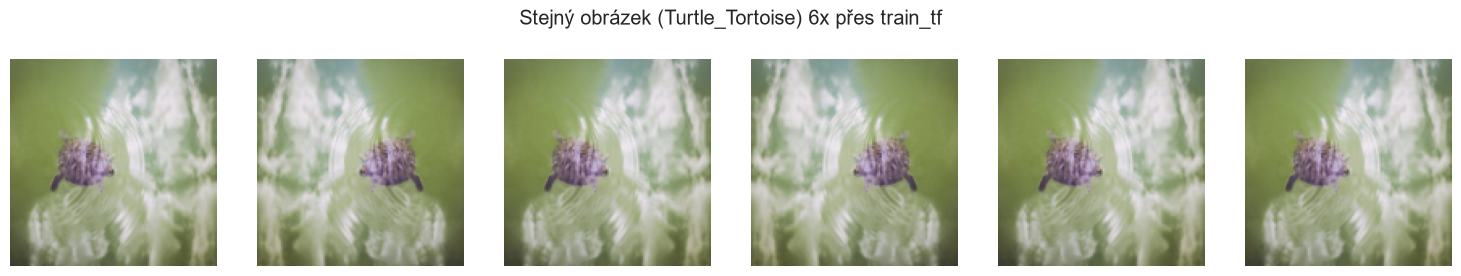

In [21]:
def denormalize(img):
    # Vrátí normalizovaný tenzor (3, H, W) zpět do rozsahu 0-1, aby šel zobrazit.
    mean = MEAN.view(3, 1, 1)            # (3,) -> (3, 1, 1), aby se broadcastovalo přes H a W
    std  = STD.view(3, 1, 1)
    return (img * std + mean).clamp(0, 1)

fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
for ax in axes:
    img, lbl = train_ds[0]                # pokaždé znovu prochází transformací
    ax.imshow(denormalize(img).permute(1, 2, 0))   # (C, H, W) -> (H, W, C) pro matplotlib
    ax.axis("off")
fig.suptitle(f"Stejný obrázek ({idx_to_class[lbl.item()]}) 6x přes train_tf")
plt.tight_layout(); plt.show()

## 🚚 DataLoader

`DataLoader` vezme náš `Dataset` a stará se o:

- **batchování** (`batch_size=64`) — zavolá 64× `__getitem__` a výsledky „složí“ (*collate*) do jednoho
  tenzoru `(64, 3, 128, 128)`. Proto musí mít všechny obrázky stejný tvar.
- **míchání** (`shuffle=True`) — **jen u trénovacích dat**. Každou epochu jiné pořadí ⇒ batche nejsou
  pořád stejné a model se nenaučí nic z pořadí dat. U validace míchat nemusíme — výsledek na celé sadě je stejný.
- **workery** (`num_workers=4`) — načítání a transformace obrázků běží paralelně ve 4 dalších procesech
  na CPU, zatímco GPU počítá. S `num_workers=0` by se vše dělalo v hlavním procesu a GPU by čekala na disk.
- **`pin_memory=True`** — data se ukládají do „připnuté“ paměti RAM, odkud je kopírování na GPU rychlejší.
  Má smysl jen pokud máme GPU.
- **`persistent_workers=True`** — workery se **nevypínají na konci epochy**. Na Windows trvá spuštění
  každého workeru několik sekund (musí znovu načíst Python a PyTorch), takže bez toho bychom tuto cenu
  platili na začátku *každé* epochy (train i val).

In [22]:
PIN_MEMORY = torch.cuda.is_available()
loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0)

train_loader = DataLoader(train_ds, shuffle=True,  **loader_kwargs)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_kwargs)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_kwargs)

print("batchů v train_loader:", len(train_loader))   # = ceil(len(train_ds) / BATCH_SIZE)
print("batchů ve val_loader:  ", len(val_loader))
print("batchů v test_loader:  ", len(test_loader))

batchů v train_loader: 149
batchů ve val_loader:   32
batchů v test_loader:   32


### ⏱️ Má `num_workers` vůbec vliv?

Krátký experiment: pro různý počet workerů změříme **dvě věci zvlášť**:
- **start** — vytvoření iterátoru `iter(loader)` + první batch. Na Windows se tady spouští workery
  (každý je nový proces Pythonu, který musí znovu načíst PyTorch ⇒ několik sekund na worker),
- **načítání** — čas na dalších 60 batchů, když už workery běží. To je to, co nás zajímá během tréninku.

Kdybychom měřili jen celkový čas na pár batchů, start workerů by výsledek zkreslil a workery by
paradoxně vyšly *pomalejší* než `num_workers=0`.

In [23]:
def time_loader(n_workers, n_batches=60):
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=n_workers)
    t0 = time.perf_counter()
    it = iter(loader)                          # na Windows tady se spouští workery
    next(it)                                   # první batch
    t1 = time.perf_counter()
    for _ in range(n_batches):                 # dalších n_batches už s běžícími workery
        next(it)
    t2 = time.perf_counter()
    return t1 - t0, t2 - t1

for w in [0, 2, 4]:
    start, load = time_loader(w)
    print(f"num_workers={w}: start {start:5.2f} s | dalších 60 batchů {load:5.2f} s "
          f"({60 * BATCH_SIZE / load:5.0f} obrázků/s)")

num_workers=0: start  0.11 s | dalších 60 batchů  5.75 s (  668 obrázků/s)


num_workers=2: start  4.98 s | dalších 60 batchů  4.46 s (  860 obrázků/s)


num_workers=4: start  9.82 s | dalších 60 batchů  2.96 s ( 1298 obrázků/s)


## 🖼️ Vizualizace jednoho batche

Tohle je přesně to, co **dostane model na vstup**. Kontrolujeme:
- **tvar** obrázků `(B, C, H, W)` = `(64, 3, 128, 128)` a labelů `(64,)`,
- **datové typy** (`float32` pro obrázky, `int64` pro labely),
- **rozsah hodnot** po normalizaci (zhruba okolo 0, ne 0–255),
- že **obrázky odpovídají svým labelům** (žádné prohození indexů).

Pro zobrazení musíme normalizaci vrátit zpět (`denormalize`) a přehodit osy na `(H, W, C)`,
protože matplotlib očekává kanály na konci.

In [24]:
images, labels = next(iter(train_loader))

print("images:", tuple(images.shape), images.dtype)   # (64, 3, 128, 128) = (batch, kanály, výška, šířka)
print("labels:", tuple(labels.shape), labels.dtype)   # (64,)
print("průměr po kanálech:", [round(v, 2) for v in images.mean(dim=(0, 2, 3)).tolist()])   # ~0
print("std po kanálech:   ", [round(v, 2) for v in images.std(dim=(0, 2, 3)).tolist()])    # ~1
print("rozsah labelů:", labels.min().item(), "-", labels.max().item(), f"(platné: 0 - {N_CLASSES - 1})")

assert images.shape == (images.shape[0], 3, IMG_SIZE, IMG_SIZE)
assert labels.shape == (images.shape[0],)
assert labels.min() >= 0 and labels.max() < N_CLASSES

images: (64, 3, 128, 128) torch.float32
labels: (64,) torch.int64
průměr po kanálech: [-0.03, -0.07, 0.01]
std po kanálech:    [0.98, 1.04, 1.02]
rozsah labelů: 0 - 22 (platné: 0 - 22)


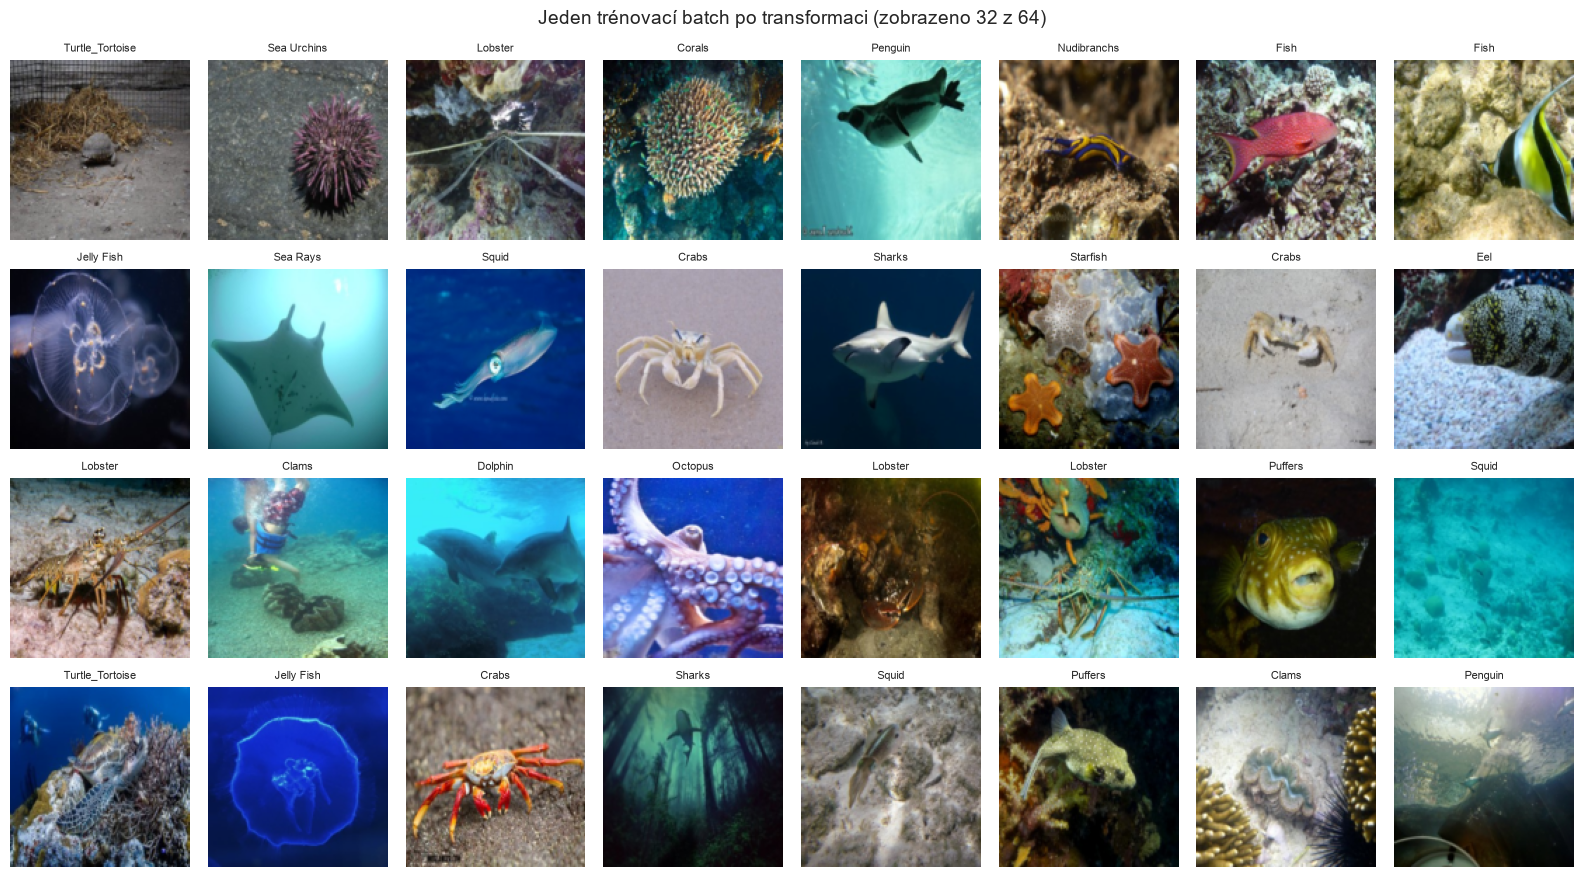

In [25]:
n_show = 32
fig, axes = plt.subplots(4, 8, figsize=(16, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(denormalize(images[i]).permute(1, 2, 0))
    ax.set_title(idx_to_class[labels[i].item()], fontsize=8)
    ax.axis("off")
fig.suptitle(f"Jeden trénovací batch po transformaci (zobrazeno {n_show} z {len(images)})", fontsize=14)
plt.tight_layout(); plt.show()

## 📝 Shrnutí Části 1

- **Split:** stratifikovaně 70 / 15 / 15 ⇒ train **9 515** / val **2 039** / test **2 040** obrázků.
  Podíly tříd se mezi sadami liší nejvýš o **0,04 %** ⇒ stratifikace funguje. Sady se nepřekrývají (ověřeno assertem).
  Test set necháváme stranou až na finální vyhodnocení.
- **Normalizace:** mean = (0,321; 0,405; 0,417), std = (0,261; 0,238; 0,258) spočítané z 2 000 trénovacích obrázků.
  Oproti ImageNetu (0,485; 0,456; 0,406) má náš dataset výrazně **méně červené** (0,32 vs. 0,49), zatímco modrá je
  podobná ⇒ převažuje modrozelená. Odpovídá to podvodním fotkám: voda pohlcuje červené světlo nejdřív.
  Proto dává smysl počítat vlastní statistiky místo převzetí hodnot z ImageNetu.
- **Dataset:** `SeaAnimalsDataset` (uložený do `dataset.py` kvůli workerům na Windows) načítá obrázky líně
  v `__getitem__`, převádí je na RGB a vrací `(tenzor (3, 128, 128) float32, label int64)`.
- **DataLoader:** batch 64 ⇒ 149 trénovacích a 32 validačních batchů, shuffle jen u train, `num_workers=4`,
  `pin_memory`, `persistent_workers`. Měření: 0 workerů ≈ 580 obr./s, 2 workery ≈ 790 obr./s, 4 workery ≈ 1 080 obr./s
  (**~1,9× rychlejší**; mezi spuštěními se čísla mírně liší). Cena je start workerů ≈ 11 s (na Windows nový proces Pythonu pro každý worker) — díky
  `persistent_workers=True` ji zaplatíme jen jednou, ne na začátku každé epochy.
- **Batch:** tvar `(64, 3, 128, 128)`, labely `(64,)` v rozsahu 0–22. Po normalizaci jsou průměry kanálů blízko 0
  a std ≈ 1 ⇒ normalizace funguje. Obrázky ve vizualizaci odpovídají svým labelům.

> 💡 Načítání dat je pořád pomalejší než GPU (malá CNN zvládne na GTX 1080 jeden krok s batchem 64 zhruba za 16 ms,
> tj. ~4 000 obr./s). Úzkým hrdlem tréninku tedy bude dekódování JPEGů na CPU, ne výpočet sítě.

**Další krok (Část 2):** baseline CNN od nuly (`nn.Module`) a kontrola tvarů vstupu a výstupu.

# 🧠 Část 2 — Baseline CNN

Teď navrhneme **první model** — jednoduchou konvoluční síť (CNN) **od nuly, bez předtrénovaných vah**.
Cílem není co nejlepší výsledek, ale zjistit, co zvládne malá síť sama (*neasistovaný výkon*). To číslo
pak bude výchozí bod, se kterým budeme v dalších milestonech porovnávat vylepšení.

**Proč CNN a ne obyčejná plně propojená síť (MLP):** obrázek 3 × 128 × 128 má 49 152 čísel. MLP by každý pixel
spojila s každým neuronem zvlášť (obrovské množství vah) a nevěděla by, které pixely jsou sousední.
Konvoluce používá **malý filtr 3 × 3, který se posouvá po celém obrázku** — stejné váhy hledají stejný vzor
(hranu, texturu, oko…) kdekoliv v obrázku. To je pro obrázky přesně to správné.

## 🏗️ Architektura

Tři stejné bloky **Conv → ReLU → MaxPool** a nakonec jedna lineární vrstva:

| Vrstva | Co dělá | Tvar výstupu `(B, C, H, W)` |
|---|---|---|
| vstup | batch obrázků | `(B, 3, 128, 128)` |
| `Conv2d(3 → 16, 3×3, padding=1)` + `ReLU` | 16 filtrů hledá jednoduché vzory (hrany, barvy) | `(B, 16, 128, 128)` |
| `MaxPool2d(2)` | z každého okna 2 × 2 nechá maximum ⇒ poloviční rozlišení | `(B, 16, 64, 64)` |
| `Conv2d(16 → 32)` + `ReLU` + `MaxPool2d(2)` | kombinuje vzory do složitějších (textury, tvary) | `(B, 32, 32, 32)` |
| `Conv2d(32 → 64)` + `ReLU` + `MaxPool2d(2)` | ještě složitější části (ploutev, ulita…) | `(B, 64, 16, 16)` |
| `Flatten` | „rozbalí“ mapu na jeden vektor: 64 · 16 · 16 | `(B, 16384)` |
| `Linear(16384 → 23)` | z vektoru spočítá **skóre (logit) pro každou z 23 tříd** | `(B, 23)` |

**Proč tahle rozhodnutí:**
- **`padding=1`** — okolo obrázku se přidá rámeček nul, takže filtr 3 × 3 nezmenší rozměr (128 → 128).
  Zmenšování necháváme jen na `MaxPool`, takže se tvary snadno počítají: 128 → 64 → 32 → 16.
- **Kanály rostou 16 → 32 → 64, rozlišení klesá** — čím hlouběji, tím méně „kde“ a víc „co“.
  Zdvojnásobení kanálů při polovičním rozlišení je běžné pravidlo (výpočet na vrstvu zůstává podobný).
- **`ReLU`** (max(0, x)) — nelinearita. Bez ní by šlo několik vrstev za sebou nahradit jednou lineární operací
  a hloubka by nic nepřinesla.
- **3 konvoluční vrstvy** — odpovídá zadání „jednoduchá 2–3vrstvá CNN“.
- **Na konci žádný `Softmax`** — model vrací surová skóre (*logity*). `nn.CrossEntropyLoss`, kterou použijeme
  v Části 3, si softmax (resp. log-softmax) počítá **sama uvnitř** a je to tak numericky stabilnější.
  Kdybychom softmax přidali i do modelu, počítal by se dvakrát a učení by se zhoršilo.

In [26]:
import math
import torch.nn as nn


class BaselineCNN(nn.Module):
    def __init__(self, n_classes, img_size=IMG_SIZE):
        super().__init__()                     # inicializace rodičovské třídy nn.Module (nutné)

        # Část, která z obrázku vytahuje vzory (features): 3x [Conv -> ReLU -> MaxPool]
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),    # (B, 3, 128, 128) -> (B, 16, 128, 128)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # -> (B, 16, 64, 64)

            nn.Conv2d(16, 32, kernel_size=3, padding=1),   # -> (B, 32, 64, 64)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # -> (B, 32, 32, 32)

            nn.Conv2d(32, 64, kernel_size=3, padding=1),   # -> (B, 64, 32, 32)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # -> (B, 64, 16, 16)
        )

        # 3x MaxPool(2) zmenší obrázek 2^3 = 8x  =>  128 / 8 = 16
        flat_size = 64 * (img_size // 8) * (img_size // 8)  # 64 * 16 * 16 = 16384

        # Část, která z vytažených vzorů rozhodne o třídě
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  # (B, 64, 16, 16) -> (B, 16384)
            nn.Linear(flat_size, n_classes),               # -> (B, 23) = logity, BEZ softmaxu
        )

    def forward(self, x):
        # forward říká, jak data tečou sítí; backward (gradienty) PyTorch odvodí sám
        x = self.features(x)
        x = self.classifier(x)
        return x

### Vytvoření modelu a počet parametrů

- `torch.manual_seed(SEED)` těsně před vytvořením modelu ⇒ **náhodné počáteční váhy** budou při každém spuštění stejné.
- `.to(device)` přesune všechny váhy na GPU. Data musí být později na stejném zařízení jako model.
- Parametry spočítáme po vrstvách: u konvoluce je to `výstupní kanály × vstupní kanály × 3 × 3` vah + 1 bias
  na každý výstupní kanál, u lineární vrstvy `vstupy × výstupy` + 1 bias na výstup.

In [27]:
torch.manual_seed(SEED)
model = BaselineCNN(n_classes=N_CLASSES).to(device)
print(model)

print(f"\n{'parametr':<22} {'tvar':<20} {'počet':>9}")
for name, p in model.named_parameters():
    print(f"{name:<22} {str(tuple(p.shape)):<20} {p.numel():>9,}")

n_params = sum(p.numel() for p in model.parameters())
n_fc = model.classifier[1].weight.numel() + model.classifier[1].bias.numel()
print(f"\nCelkem parametrů: {n_params:,}  (z toho lineární vrstva {n_fc:,} = {n_fc / n_params:.0%})")
print("Model je na:", next(model.parameters()).device)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=23, bias=True)
  )
)

parametr               tvar                     počet
features.0.weight      (16, 3, 3, 3)              432
features.0.bias        (16,)                       16
features.3.weight      (32, 16, 3, 3)           4,608
features.3.bias        (32,)                       32
features.6.weight      

> 💡 **Kde jsou parametry:** všechny tři konvoluce mají dohromady jen ~23 tisíc vah, zatímco poslední
> lineární vrstva má ~377 tisíc (94 %). Konvoluce sdílí malý filtr 3 × 3 po celém obrázku, kdežto
> `Linear` propojuje každé ze 16 384 čísel s každou z 23 tříd. Celkem ~400 tisíc parametrů je na dnešní
> poměry **velmi malá síť** (ResNet-18 má ~11 milionů) — přesně to od baseline chceme.

## 🔍 Kontrola tvarů a výstupu na skutečném batchi

Než začneme trénovat, pošleme sítí **jeden skutečný batch** z Části 1 a ověříme:
1. **tvar po každé vrstvě** — sedí s tabulkou výše? (chyba v `flat_size` by se projevila právě tady),
2. **tvar výstupu** `(64, 23)` — jeden řádek skóre pro každý obrázek, jeden sloupec pro každou třídu,
3. **loss při náhodných vahách** — model ještě nic neumí, takže by měl dávat každé třídě zhruba stejnou
   pravděpodobnost $1/23$. Cross-entropy je pak $-\ln(1/23) = \ln 23 \approx 3{,}14$.
   Pokud by vyšla výrazně jinak, je chyba v modelu nebo v labelech **ještě před tréninkem**.

`torch.no_grad()` — jen se díváme, nepotřebujeme gradienty ⇒ PyTorch si nemusí pamatovat mezivýsledky a ušetří paměť.

In [28]:
x = images.to(device)           # batch z Části 1: (64, 3, 128, 128)
y = labels.to(device)           # (64,)

with torch.no_grad():
    print(f"{'vstup':<14} {tuple(x.shape)}")
    h = x
    for layer in list(model.features) + list(model.classifier):   # projdeme vrstvy jednu po druhé
        h = layer(h)
        print(f"{layer.__class__.__name__:<14} {tuple(h.shape)}")

    logits = model(x)                                   # celý forward najednou
    loss = nn.CrossEntropyLoss()(logits, y)
    probs = torch.softmax(logits, dim=1)                # softmax jen pro výpis, model ho nemá

assert logits.shape == (x.shape[0], N_CLASSES)
assert torch.allclose(h, logits)                        # vrstva po vrstvě = celý forward
print(f"\n✅ Výstup modelu: {tuple(logits.shape)} = (batch, počet tříd)")
print(f"loss při náhodných vahách: {loss.item():.3f}   (očekáváme ln({N_CLASSES}) = {math.log(N_CLASSES):.3f})")
print(f"průměrná pravděpodobnost tipnuté třídy: {probs.max(dim=1).values.mean():.3f}   (rovnoměrně by bylo 1/{N_CLASSES} = {1 / N_CLASSES:.3f})")

vstup          (64, 3, 128, 128)
Conv2d         (64, 16, 128, 128)
ReLU           (64, 16, 128, 128)
MaxPool2d      (64, 16, 64, 64)
Conv2d         (64, 32, 64, 64)
ReLU           (64, 32, 64, 64)
MaxPool2d      (64, 32, 32, 32)
Conv2d         (64, 64, 32, 32)
ReLU           (64, 64, 32, 32)
MaxPool2d      (64, 64, 16, 16)
Flatten        (64, 16384)
Linear         (64, 23)



✅ Výstup modelu: (64, 23) = (batch, počet tříd)


loss při náhodných vahách: 3.138   (očekáváme ln(23) = 3.135)
průměrná pravděpodobnost tipnuté třídy: 0.048   (rovnoměrně by bylo 1/23 = 0.043)


## 📝 Shrnutí Části 2

- **Model:** `BaselineCNN` — 3 bloky Conv(3 × 3, padding 1) → ReLU → MaxPool(2) s kanály 3 → 16 → 32 → 64,
  pak `Flatten` a jedna vrstva `Linear(16384 → 23)`. Bez předtrénovaných vah, váhy jsou náhodné (seed 42).
- **Tvary:** `(B, 3, 128, 128)` → `(B, 16, 64, 64)` → `(B, 32, 32, 32)` → `(B, 64, 16, 16)` → `(B, 16384)` → `(B, 23)`.
  Ověřeno vrstvu po vrstvě na skutečném batchi i assertem — vstup odpovídá datům (RGB 128 × 128),
  výstup úloze (23 tříd).
- **Velikost:** ~400 tisíc parametrů, z toho 94 % v poslední lineární vrstvě.
- **Výstup jsou logity bez softmaxu** — softmax je součástí `nn.CrossEntropyLoss`.
- **Sanity check před tréninkem:** loss s náhodnými vahami vychází blízko $\ln 23 \approx 3{,}14$ ⇒ model na začátku
  nemá žádnou „předpojatost“ k některé třídě a výstup je napojený na labely správně.

**Další krok (Část 3):** ruční trénovací a validační smyčka, sledování loss a accuracy přes epochy.

# 🔁 Část 3 — Tréninková a validační smyčka

Smyčku píšeme **celou ručně** (žádný hotový `fit()`), abychom viděli každý krok učení.
Jedna **epocha** = model jednou projde všechna trénovací data. V každé epoše:

1. **Trénink** (`model.train()`) — pro každý batch: predikce → chyba (loss) → gradienty → úprava vah.
2. **Validace** (`model.eval()` + `torch.no_grad()`) — jen měříme, jak model funguje na datech, která nikdy neviděl při učení. Váhy se nemění.

## ⚙️ Nastavení: loss, optimizer, počet epoch

| Volba | Hodnota | Proč |
|---|---|---|
| Loss | `nn.CrossEntropyLoss()` | standard pro klasifikaci do více tříd. Uvnitř spočítá log-softmax z logitů a trestá model tím víc, čím menší pravděpodobnost dal **správné** třídě: $-\ln p_\text{správná}$ |
| Optimizer | `Adam`, `lr = 1e-3` | Adam si pro každou váhu sám přizpůsobuje velikost kroku ⇒ funguje dobře „z krabice“ bez ladění. `1e-3` je jeho obvyklá výchozí hodnota. Obyčejné SGD by potřebovalo pečlivě vyladit learning rate a momentum |
| Epochy | 15 | dost na to, aby se ukázal trend (a případné přeučení), a přitom trénink trvá jen pár minut |

**Model vytváříme znovu** se stejným seedem — buňka tak začíná vždy od čerstvých náhodných vah a jde spustit
opakovaně (jinak by druhé spuštění pokračovalo v tréninku už natrénovaného modelu).

In [29]:
EPOCHS = 15
LR = 1e-3

torch.manual_seed(SEED)
model = BaselineCNN(n_classes=N_CLASSES).to(device)        # čerstvý model s náhodnými vahami

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)   # optimizer dostane váhy, které má upravovat

## 🏋️ Jedna trénovací epocha

Pět kroků pro každý batch — tohle je **jádro celého deep learningu**:

| Krok | Kód | Co se děje |
|---|---|---|
| 1 | `optimizer.zero_grad()` | **vynuluje staré gradienty**. PyTorch gradienty při každém `backward()` **přičítá**, takže bez vynulování by se sčítaly přes všechny batche |
| 2 | `logits = model(x)` | **forward**: predikce, tvar `(B, 23)` |
| 3 | `loss = criterion(logits, y)` | jedno číslo: jak moc se model v tomto batchi spletl (průměr přes batch) |
| 4 | `loss.backward()` | **backpropagation**: spočítá gradient loss podle *každé* ze 400 tisíc vah (uloží do `.grad`) |
| 5 | `optimizer.step()` | upraví váhy kousek proti směru gradientu ⇒ loss by měla klesnout |

**Ruční akumulace metrik přes batche:**
- `loss.item()` je **průměr** přes batch. Abychom dostali správný průměr přes celou epochu, násobíme ho velikostí
  batche a na konci dělíme celkovým počtem vzorků. Poslední batch je totiž menší (9 515 = 148 · 64 + **43**)
  — prostý průměr batchových průměrů by mu dal stejnou váhu jako plným batchům.
- **Accuracy:** `logits.argmax(dim=1)` vybere v každém řádku index největšího skóre = predikovaná třída.
  Porovnáme s labely, `True` = 1, sečteme ⇒ počet správných.
- `.item()` převede tenzor na obyčejné Python číslo — jinak bychom si v součtech drželi celý výpočetní graf a plnila by se paměť GPU.

`non_blocking=True` — díky `pin_memory=True` v DataLoaderu se kopírování na GPU může překrývat s výpočtem.

In [30]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()                                   # režim tréninku (důležité pro Dropout/BatchNorm, viz níže)
    total_loss, correct, n = 0.0, 0, 0

    for x, y in loader:                             # x .. img, y .. label, cyklus pro každý batch
        x = x.to(device, non_blocking=True)         # (B, 3, 128, 128); sends data to GPU
        y = y.to(device, non_blocking=True)         # (B,)

        optimizer.zero_grad()                       # 1) vynulovat staré gradienty
        logits = model(x)                           # 2) forward -> (B, 23)
        loss = criterion(logits, y)                 # 3) chyba = průměr přes batch
        loss.backward()                             # 4) gradienty pro všechny váhy, backpropagace
        optimizer.step()                            # 5) úprava vah
        # Pořadí operací: vynuluj → předpověz → změř chybu → spočítej, kam se pohnout → pohni se.

        # ruční akumulace metrik přes batche
        total_loss += loss.item() * y.size(0)       # průměr batche * počet vzorků = součet
        correct    += (logits.argmax(dim=1) == y).sum().item()
        n          += y.size(0)

    return total_loss / n, correct / n              # průměrná loss a accuracy za celou epochu

## 🧪 Validace

Validační funkce je skoro stejná, ale **bez kroků 1, 4 a 5** — model se z validačních dat nesmí nic naučit.

- **`model.eval()`** přepne vrstvy, které se při tréninku a vyhodnocení chovají jinak (`Dropout` se vypne,
  `BatchNorm` použije uložené statistiky). Náš baseline tyto vrstvy zatím nemá, takže se výsledek nezmění —
  ale je to **správný zvyk**: až je v dalších milestonech přidáme, validace bude fungovat bez úprav.
  Proto také `train_one_epoch` na začátku volá `model.train()` (přepne zpět).
- **`torch.no_grad()`** — PyTorch si nebude pamatovat mezivýsledky pro výpočet gradientů ⇒ validace je rychlejší
  a zabere méně paměti GPU. A zároveň máme jistotu, že omylem nic neupravíme.

In [31]:
def evaluate(model, loader, criterion):
    model.eval()                                    # režim vyhodnocení
    total_loss, correct, n = 0.0, 0, 0

    with torch.no_grad():                           # žádné gradienty
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            total_loss += loss.item() * y.size(0)
            correct    += (logits.argmax(dim=1) == y).sum().item()
            n          += y.size(0)

    return total_loss / n, correct / n

## 🚀 Trénink

Po každé epoše spustíme validaci a všechna čísla si uložíme do slovníku `history` (pro grafy).
Test set **nepoužíváme** — ten zůstává schovaný až na finální vyhodnocení v pozdějších milestonech.

> ⏱️ První epocha je o ~10 s delší — startují workery DataLoaderu (viz Část 1). Díky `persistent_workers=True`
> se to stane jen jednou.

In [32]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

t_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc     = evaluate(model, val_loader, criterion)

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss);     history["val_acc"].append(val_acc)

    print(f"epocha {epoch:2d}/{EPOCHS} | train loss {train_loss:.3f}, acc {train_acc:6.1%} "
          f"| val loss {val_loss:.3f}, acc {val_acc:6.1%} | {time.perf_counter() - t0:4.1f} s")

print(f"\nCelkový čas tréninku: {(time.perf_counter() - t_start) / 60:.1f} min")
best_epoch = int(np.argmax(history["val_acc"])) + 1
print(f"Nejlepší val accuracy: {max(history['val_acc']):.1%} (epocha {best_epoch})")

epocha  1/15 | train loss 2.477, acc  27.0% | val loss 2.258, acc  32.8% | 17.0 s


epocha  2/15 | train loss 2.124, acc  36.0% | val loss 2.142, acc  36.0% |  5.2 s


epocha  3/15 | train loss 1.929, acc  41.6% | val loss 2.059, acc  37.5% |  5.6 s


epocha  4/15 | train loss 1.792, acc  45.7% | val loss 2.017, acc  39.2% |  5.2 s


epocha  5/15 | train loss 1.630, acc  50.3% | val loss 1.954, acc  41.7% |  5.1 s


...

epocha 11/15 | train loss 0.664, acc  80.2% | val loss 2.625, acc  41.2% |  5.2 s


epocha 12/15 | train loss 0.541, acc  84.2% | val loss 2.746, acc  42.2% |  5.3 s


epocha 13/15 | train loss 0.451, acc  86.6% | val loss 2.927, acc  41.9% |  5.5 s


epocha 14/15 | train loss 0.366, acc  89.5% | val loss 3.343, acc  40.7% |  5.9 s


epocha 15/15 | train loss 0.307, acc  91.1% | val loss 3.392, acc  41.1% |  5.1 s

Celkový čas tréninku: 1.5 min
Nejlepší val accuracy: 42.9% (epocha 10)


## 📈 Křivky učení

Dva grafy přes epochy — **train vs. val** pro loss a accuracy. Na co se díváme:
- **Obě loss klesají** ⇒ model se učí obecné vzory.
- **Train loss klesá, ale val loss stoupá** ⇒ **přeučení (overfitting)**: model si začíná pamatovat trénovací
  obrázky místo toho, aby se učil, jak zvířata vypadají.
- Do grafu accuracy přidáme i **naivní baseline** z Části 0 (vždy nejčastější třída = 13,9 %) a náhodné tipování (1/23).

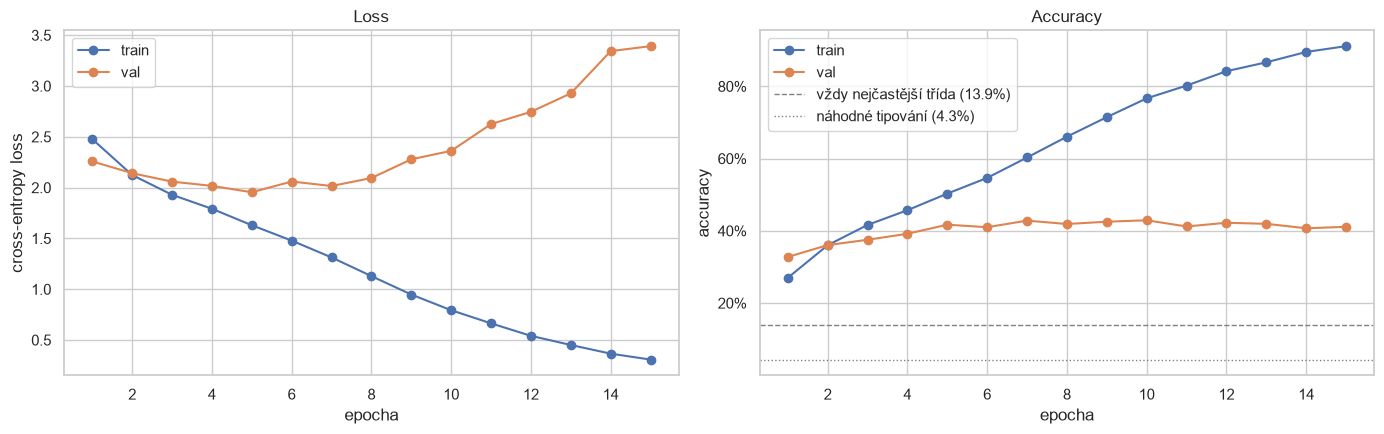

In [33]:
epochs = range(1, EPOCHS + 1)
majority_acc = class_counts.iloc[0] / len(df)              # z Části 0: vždy „Turtle_Tortoise“

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(epochs, history["train_loss"], "o-", label="train")
axes[0].plot(epochs, history["val_loss"],   "o-", label="val")
axes[0].set_xlabel("epocha"); axes[0].set_ylabel("cross-entropy loss"); axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(epochs, history["train_acc"], "o-", label="train")
axes[1].plot(epochs, history["val_acc"],   "o-", label="val")
axes[1].axhline(majority_acc,    color="gray", ls="--", lw=1, label=f"vždy nejčastější třída ({majority_acc:.1%})")
axes[1].axhline(1 / N_CLASSES,   color="gray", ls=":",  lw=1, label=f"náhodné tipování ({1 / N_CLASSES:.1%})")
axes[1].set_xlabel("epocha"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()

plt.tight_layout(); plt.show()

## ⚖️ Accuracy po třídách (validace)

Třídy jsou nevyvážené (Turtle_Tortoise má 4,6× víc obrázků než Seal), takže celková accuracy může skrývat,
že model některé třídy skoro nepoznává. Spočítáme proto accuracy **zvlášť pro každou třídu**:

- projdeme validaci a posbíráme všechny predikce,
- `torch.bincount(labels, minlength=23)` spočítá, kolik obrázků má každá třída,
- `torch.bincount(labels[preds == labels], ...)` spočítá, kolik z nich model trefil.

**Macro accuracy** = průměr accuracy přes třídy (každá třída má stejnou váhu bez ohledu na velikost).
Když je výrazně nižší než celková accuracy, model „nadržuje“ velkým třídám.

celková accuracy: 41.1% | macro accuracy (průměr přes třídy): 37.4%


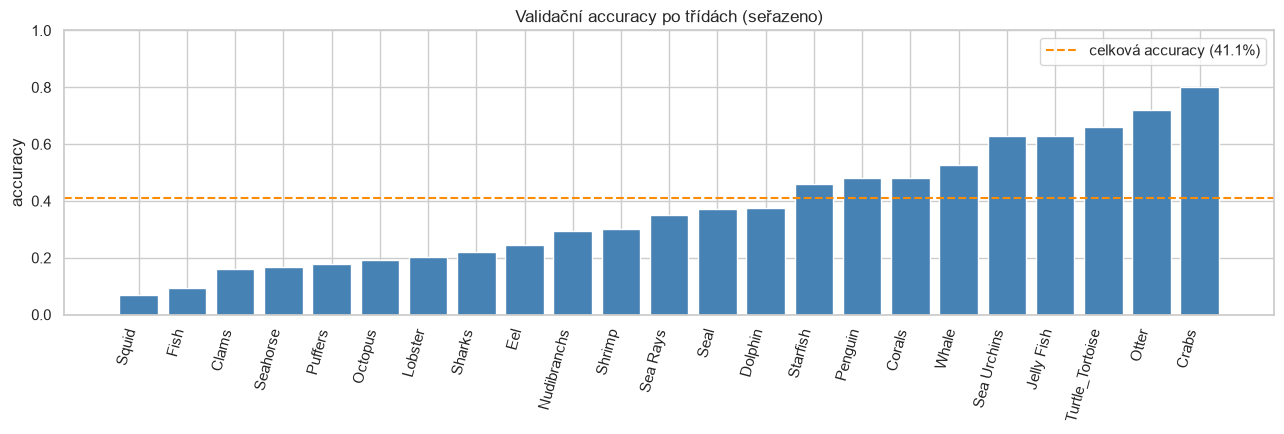

Nejhorší 3: Squid 7%, Fish 9%, Clams 16%
Nejlepší 3: Crabs 80%, Otter 72%, Turtle_Tortoise 66%


In [34]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in val_loader:
        all_preds.append(model(x.to(device)).argmax(dim=1).cpu())
        all_labels.append(y)
preds  = torch.cat(all_preds)                   # (2039,)
labels_val = torch.cat(all_labels)              # (2039,)

total_per_class   = torch.bincount(labels_val, minlength=N_CLASSES)
correct_per_class = torch.bincount(labels_val[preds == labels_val], minlength=N_CLASSES)
acc_per_class = (correct_per_class / total_per_class).numpy()

overall_acc = (preds == labels_val).float().mean().item()
print(f"celková accuracy: {overall_acc:.1%} | macro accuracy (průměr přes třídy): {acc_per_class.mean():.1%}")

order = np.argsort(acc_per_class)               # od nejhorší třídy po nejlepší
plt.figure(figsize=(13, 4.5))
plt.bar([idx_to_class[i] for i in order], acc_per_class[order], color="steelblue")
plt.axhline(overall_acc, color="darkorange", ls="--", lw=1.5, label=f"celková accuracy ({overall_acc:.1%})")
plt.xticks(rotation=75, ha="right"); plt.ylabel("accuracy"); plt.ylim(0, 1)
plt.title("Validační accuracy po třídách (seřazeno)")
plt.legend(); plt.tight_layout(); plt.show()

print("Nejhorší 3:", ", ".join(f"{idx_to_class[i]} {acc_per_class[i]:.0%}" for i in order[:3]))
print("Nejlepší 3:", ", ".join(f"{idx_to_class[i]} {acc_per_class[i]:.0%}" for i in order[::-1][:3]))

## 📝 Shrnutí Části 3

- **Smyčka:** ruční trénink (`zero_grad` → forward → loss → `backward` → `step`) a oddělená validace
  (`model.eval()` + `torch.no_grad()`). Loss i accuracy se sčítají ručně přes batche (vážené velikostí batche).
  Adam, lr = 1e-3, 15 epoch, ~6 s na epochu na GTX 1080 (první epocha ~20 s kvůli startu workerů), celkem ~2 min.
- **Výsledek:** nejlepší **val accuracy 42,9 %** (epocha 10), na konci 41,1 %. To je **~3× víc než naivní baseline**
  „vždy nejčastější třída“ (13,9 %) a ~10× víc než náhodné tipování (4,3 %) ⇒ model se opravdu učí rozpoznávat zvířata.
- **Přeučení (overfitting) je jasně vidět:**
  - train accuracy stoupá až na **91 %**, validační se od ~5. epochy drží kolem **41–43 %**,
  - **val loss je nejnižší v 5. epoše (1,95)** a pak **stoupá** až na 3,39, zatímco train loss dál klesá k 0,31.
  - Model si tedy po ~5 epochách začne **pamatovat trénovací obrázky** místo učení obecných vzorů. Val loss roste,
    i když val accuracy skoro stagnuje, protože model je u chybných predikcí čím dál **sebejistější**
    (cross-entropy za sebejistou chybu trestá hodně).
  - Odpovídá to očekávání: síť bez regularizace (žádný Dropout, BatchNorm, jen mírná augmentace) má ~400 tisíc
    parametrů a jen ~9,5 tisíce trénovacích obrázků.
- **Po třídách:** macro accuracy 37,4 % < celková 41,1 % ⇒ velké rozdíly mezi třídami.
  - Nejlépe: Crabs 80 %, Otter 72 %, Turtle_Tortoise 66 % — výrazný tvar/barva, u želv i nejvíc dat.
  - Nejhůř: **Squid 7 %**, Fish 9 %, Clams 16 %. „Fish“ je velmi různorodá třída (tisíce druhů ryb) a vizuálně
    se překrývá s jinými (Puffers, Sharks, Eel…), Squid je zase podobná třídě Octopus. Nejmenší třída Seal přitom
    mezi nejhoršími není ⇒ **víc než počet obrázků rozhoduje podobnost tříd**.
  - Pozn.: čísla po třídách jsou z modelu po 15. epoše (už přeučeného), ne z nejlepší epochy.
- **Reprodukovatelnost:** díky pevnému seedu a `torch.backends.cudnn.deterministic = True` (buňka s importy)
  dává notebook při každém spuštění **stejná čísla** (ověřeno dvěma běhy). Bez toho cuDNN na GPU volí rychlejší,
  ale nedeterministické algoritmy a výsledky se liší o ~±1 %. Na jiné GPU/verzi knihoven se čísla mohou mírně lišit.

> 💡 **Co z toho plyne pro další milestony:** zastavit trénink kolem nejlepší epochy (*early stopping*, uložení
> nejlepších vah), silnější augmentace (výřezy, rotace), regularizace (Dropout, weight decay), BatchNorm,
> a hlavně **transfer learning** z předtrénované sítě, který na takto malém datasetu obvykle pomůže nejvíc.

**Další krok (Část 4):** overfit sanity check — ověříme, že model dokáže 16 vzorků naučit na loss ≈ 0 a 100 % accuracy.

# 🧪 Část 4 — Overfit sanity check

**Myšlenka:** vezmeme jen **16 obrázků** a necháme model trénovat jen na nich. Síť se ~400 tisíci parametry
si 16 obrázků musí dokázat **zapamatovat úplně** ⇒ loss ≈ 0 a accuracy 100 %.

Tady je přeučení **záměrné** — netestujeme, jestli model zobecňuje, ale jestli **pipeline vůbec funguje**.
Když se model nedokáže naučit ani 16 obrázků, je v kódu chyba a nemá smysl ladit nic dalšího. Typicky:

| Co by bylo špatně | Jak by se to projevilo |
|---|---|
| gradienty netečou (zapomenutý `backward()`/`step()`, váhy nejsou v optimizeru, „odpojený“ výpočet) | loss se nehne z ~3,14 |
| labely neodpovídají obrázkům (jiné pořadí, posunutý index, špatné `class_to_idx`) | model nemá co se naučit — nebo se „naučí“, ale predikce nesedí se skutečnými třídami v tabulce níže |
| chybné tvary / broadcasting (např. labely `(B, 1)` místo `(B,)`, `argmax` přes špatnou osu) | loss nebo accuracy se počítají z nesmyslně spárovaných čísel a nedosáhnou 0 / 100 % |

**Rozhodnutí:**
- **16 náhodných trénovacích obrázků** (seed 42), všechny v **jednom batchi** ⇒ 1 epocha = 1 krok optimizeru.
- **`eval_tf` (bez augmentace)** — obrázky musí být v každé epoše přesně stejné. S náhodným flipem by model
  viděl pokaždé trochu jiná data a dosažení nulové loss by bylo zbytečně těžší.
- **`num_workers=0`** — 16 obrázků se načte za zlomek sekundy; start workerů (~10 s) by trval déle než samotná práce.
- **Čerstvý model** (seed 42), stejná architektura, stejný optimizer (Adam, lr = 1e-3) a **stejné funkce
  `train_one_epoch` / `evaluate` z Části 3** ⇒ testujeme přesně ten kód, kterým trénujeme.

In [35]:
OVERFIT_N = 16
OVERFIT_EPOCHS = 50

small_df = train_df.sample(n=OVERFIT_N, random_state=SEED).reset_index(drop=True)
small_ds = SeaAnimalsDataset(small_df, transform=eval_tf)            # bez augmentace
small_loader = DataLoader(small_ds, batch_size=OVERFIT_N, shuffle=True, num_workers=0)

print("Vybrané třídy:", ", ".join(small_df["label"]))
print("Různých tříd:", small_df["label"].nunique(), "z", N_CLASSES)

torch.manual_seed(SEED)
overfit_model = BaselineCNN(n_classes=N_CLASSES).to(device)          # čerstvé náhodné váhy
overfit_optimizer = torch.optim.Adam(overfit_model.parameters(), lr=LR)

Vybrané třídy: Corals, Puffers, Sea Urchins, Crabs, Sea Urchins, Lobster, Corals, Whale, Fish, Octopus, Dolphin, Octopus, Lobster, Turtle_Tortoise, Lobster, Nudibranchs
Různých tříd: 11 z 23


### Trénink na 16 obrázcích

Po každé epoše zavoláme i `evaluate()` (`model.eval()` + `torch.no_grad()`) — měří stav **po** úpravě vah,
a je to tedy přesnější číslo než průměr, který vrací `train_one_epoch` (ta měří loss **před** krokem optimizeru).
**Epocha 0** = změření **před** tréninkem (náhodné váhy) ⇒ loss by měla být ≈ ln 23 ≈ 3,14 jako v Části 2.
Vypisujeme epochy 0–10 (tam se děje to podstatné) a pak každou 10. Loss ve **vědeckém formátu**
(`1.4e-03` = 0,0014), protože rychle klesne pod 0,00001 a s obyčejným zápisem by vypadala jako 0.

In [36]:
overfit_history = {"loss": [], "acc": []}

for epoch in range(0, OVERFIT_EPOCHS + 1):
    if epoch > 0:                                          # epocha 0 = jen měření před tréninkem
        train_one_epoch(overfit_model, small_loader, criterion, overfit_optimizer)
    loss, acc = evaluate(overfit_model, small_loader, criterion)
    overfit_history["loss"].append(loss)
    overfit_history["acc"].append(acc)
    if epoch <= 10 or epoch % 10 == 0:
        print(f"epocha {epoch:3d} | loss {loss:.1e} | accuracy {acc:6.1%}")

first_100 = next((i for i, a in enumerate(overfit_history["acc"]) if a == 1.0), None)   # index = číslo epochy
print(f"\n100 % accuracy poprvé v epoše {first_100}, konečná loss {overfit_history['loss'][-1]:.1e}")

epocha   0 | loss 3.1e+00 | accuracy   6.2%
epocha   1 | loss 2.1e+00 | accuracy  37.5%
epocha   2 | loss 1.6e+00 | accuracy  37.5%


epocha   3 | loss 9.8e-01 | accuracy  87.5%

epocha   4 | loss 4.6e-01 | accuracy 100.0%
epocha   5 | loss 2.0e-01 | accuracy 100.0%
epocha   6 | loss 6.9e-02 | accuracy 100.0%


epocha   7 | loss 2.4e-02 | accuracy 100.0%


epocha   8 | loss 9.2e-03 | accuracy 100.0%
epocha   9 | loss 3.8e-03 | accuracy 100.0%
epocha  10 | loss 1.4e-03 | accuracy 100.0%


epocha  20 | loss 3.0e-07 | accuracy 100.0%


epocha  30 | loss 3.0e-08 | accuracy 100.0%


epocha  40 | loss 2.2e-08 | accuracy 100.0%


epocha  50 | loss 1.5e-08 | accuracy 100.0%

100 % accuracy poprvé v epoše 4, konečná loss 1.5e-08


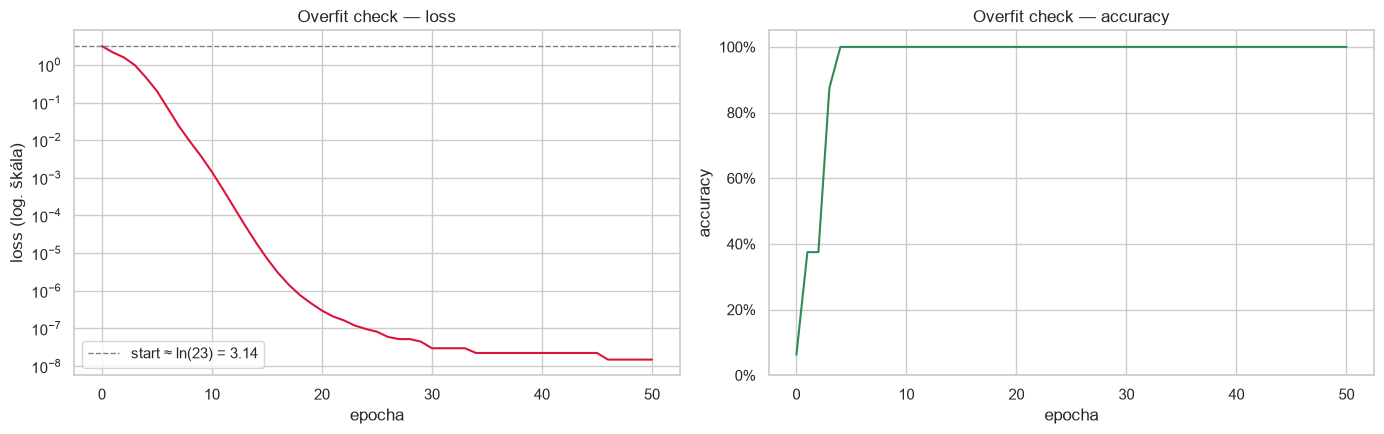

In [37]:
ep = range(0, OVERFIT_EPOCHS + 1)          # včetně epochy 0 (před tréninkem)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(ep, overfit_history["loss"], color="crimson")
axes[0].set_yscale("log")                                  # log škála: je vidět i 0,1 -> 0,001
axes[0].axhline(math.log(N_CLASSES), color="gray", ls="--", lw=1, label=f"start ≈ ln({N_CLASSES}) = {math.log(N_CLASSES):.2f}")
axes[0].set_xlabel("epocha"); axes[0].set_ylabel("loss (log. škála)"); axes[0].set_title("Overfit check — loss")
axes[0].legend()

axes[1].plot(ep, overfit_history["acc"], color="seagreen")
axes[1].set_ylim(0, 1.05)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_xlabel("epocha"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Overfit check — accuracy")

plt.tight_layout(); plt.show()

### Kontrola: odpovídají predikce skutečným labelům?

Nestačí vidět 100 % — ověříme **obrázek po obrázku**, že predikovaná třída je opravdu ta, která patří
ke složce, ze které obrázek pochází. Labely bereme z `small_df` (tedy z názvu složky), ne z modelu ani z DataLoaderu.
Pravděpodobnost je softmax z logitů — po přeučení by měla být u správné třídy téměř 1.

In [38]:
overfit_model.eval()
with torch.no_grad():
    x_small = torch.stack([small_ds[i][0] for i in range(OVERFIT_N)]).to(device)   # (16, 3, 128, 128), pořadí = small_df
    probs_small = torch.softmax(overfit_model(x_small), dim=1).cpu()                # (16, 23)

pred_idx = probs_small.argmax(dim=1)
check = pd.DataFrame({
    "skutečná třída (složka)": small_df["label"],
    "predikce": [idx_to_class[i.item()] for i in pred_idx],
    "pravděpodobnost": [f"{p:.4f}" for p in probs_small.max(dim=1).values.tolist()],
})
check["shoda"] = np.where(check["skutečná třída (složka)"] == check["predikce"], "✅", "❌")
display(check)

assert (pred_idx.numpy() == small_df["label_idx"].values).all(), "predikce nesedí s labely!"
assert overfit_history["loss"][-1] < 0.01, "loss se nepřiblížila nule!"
print("✅ Overfit check prošel: loss ≈ 0, 100 % accuracy, predikce odpovídají skutečným třídám.")

,skutečná třída (složka),predikce,pravděpodobnost,shoda
0,Corals,Corals,1.0000,✅
1,Puffers,Puffers,1.0000,✅
2,Sea Urchins,Sea Urchins,1.0000,✅
3,Crabs,Crabs,1.0000,✅
4,Sea Urchins,Sea Urchins,1.0000,✅
5,Lobster,Lobster,1.0000,✅
6,Corals,Corals,1.0000,✅
7,Whale,Whale,1.0000,✅
8,Fish,Fish,1.0000,✅
9,Octopus,Octopus,1.0000,✅


✅ Overfit check prošel: loss ≈ 0, 100 % accuracy, predikce odpovídají skutečným třídám.


## 📝 Shrnutí Části 4

- **Nastavení:** 16 náhodných trénovacích obrázků (11 různých tříd), `eval_tf` bez augmentace, jeden batch,
  čerstvý `BaselineCNN`, Adam lr = 1e-3, **stejné funkce `train_one_epoch` / `evaluate`** jako při skutečném tréninku.
- **Výsledek:**
  - loss **3,1** před tréninkem (≈ ln 23, náhodné váhy) → **1,4·10⁻³** v 10. epoše → **1,5·10⁻⁸** v 50. epoše,
  - accuracy **100 % od 4. epochy**, všech 16 predikcí odpovídá skutečné třídě (složce) s pravděpodobností ≈ 1,0.
  - Loss se kolem 10⁻⁸ zastaví — to je hranice přesnosti 32bitových čísel (`float32`), ne problém modelu.

**Co tím prokazujeme:**
1. **Gradienty tečou správně** — loss klesá rychle a až k nule ⇒ `zero_grad` / `backward` / `step` fungují a
   optimizer upravuje všechny váhy modelu.
2. **Labely odpovídají predikcím** — tabulka porovnává predikce s názvem složky každého obrázku (nezávisle na
   modelu i DataLoaderu) ⇒ obrázky a labely se cestou přes `Dataset` → `DataLoader` → model nikde neprohodily
   a `class_to_idx` / `idx_to_class` jsou konzistentní.
3. **Pipeline nemá tiché broadcasting bugy** — tvary jsou správně (`(16, 23)` logity vs. `(16,)` labely), loss
   i accuracy se počítají ze správně spárovaných čísel; jinak by loss nedosáhla ~0 nebo accuracy 100 %.

⇒ Nízká validační accuracy z Části 3 (~43 %) tedy **není chyba v kódu**, ale skutečný limit malé sítě
bez regularizace a předtrénování na tomto datasetu.

**Další krok (Část 5):** pokusíme se přesnost zlepšit vylepšeným modelem (stále bez předtrénovaných vah).

# 🚀 Část 5 — Vylepšený model

Baseline dosáhl ~43 % validační accuracy. Z Částí 3 a 4 víme dvě důležité věci:
- **kód je v pořádku** (overfit check prošel) ⇒ nízká přesnost není chyba v pipeline,
- **hlavní problém je přeučení** — train accuracy 91 %, val ~43 %, val loss od 5. epochy roste.

Zlepšení proto míří hlavně na **omezení přeučení** a teprve potom na **větší kapacitu** sítě.
Pořád platí zadání Milestone 1: **žádné předtrénované váhy** — síť trénujeme od nuly.

| Oblast | Baseline | Vylepšený model | Proč |
|---|---|---|---|
| Augmentace | jen flip | + náhodný výřez/zoom, mírná změna jasu/kontrastu/sytosti | model nikdy neuvidí stejný obrázek dvakrát ⇒ těžko si ho zapamatuje |
| Architektura | 3 bloky po 1 konvoluci, 16→64 kanálů | 4 bloky po 2 konvolucích, 32→256 kanálů | víc kapacity na složitější vzory |
| Normalizace | — | **BatchNorm** za každou konvolucí | stabilnější a rychlejší učení, mírně regularizuje |
| Konec sítě | Flatten → Linear (377 tis. vah) | **Global Average Pooling** → Dropout → Linear (6 tis. vah) | 94 % vah baseline bylo v poslední vrstvě — místo, kde se síť nejvíc přeučuje |
| Optimizer | Adam | **AdamW** s weight decay + **kosinové snižování lr** | weight decay brzdí příliš velké váhy, nižší lr na konci = jemné doladění |
| Epochy | 15, bere se poslední | 30, bere se **nejlepší** podle val accuracy | nepoužijeme přeučený konec tréninku |
| Nevyváženost tříd | — | **váhy tříd** v loss | chyba na malé třídě (Seal) se trestá víc než na velké (Turtle) |

Výsledky porovnáváme na **validační** sadě. Test set použijeme až jednou na konci (Část 6).

## 🔄 Silnější augmentace

| Transformace | Co dělá | Proč |
|---|---|---|
| `RandomResizedCrop(128, scale=(0.6, 1.0))` | vyřízne náhodnou část obrázku (60–100 % plochy, mírně jiný poměr stran) a zvětší ji na 128 × 128 | zvíře je pokaždé jinak velké a jinde v záběru ⇒ model se nemůže spoléhat na přesnou polohu. Nahrazuje `Resize` |
| `RandomHorizontalFlip()` | zrcadlení (jako dosud) | ryba plavající doleva je pořád ryba |
| `ColorJitter(0.2, 0.2, 0.2)` | náhodně změní jas, kontrast a sytost o ±20 % | různé osvětlení a hloubka pod vodou. **Odstín (`hue`) neměníme** — barva je u nás informativní (oranžová ryba ≠ modrá) |

Rozsahy jsou záměrně **mírné** (výřez aspoň 60 %, barvy ±20 %) — příliš silná augmentace by mohla zvíře z výřezu
úplně vyříznout nebo změnit k nepoznání. **Rotaci nepoužíváme** — u obrázků s hladinou by vytvořila
nepřirozené pohledy a černé rohy.

Validace a test dál používají `eval_tf` (bez augmentace). Pro augmentovaná trénovací data vytvoříme nový
`Dataset` a `DataLoader` — **třída `SeaAnimalsDataset` zůstává stejná**, mění se jen předaná transformace.

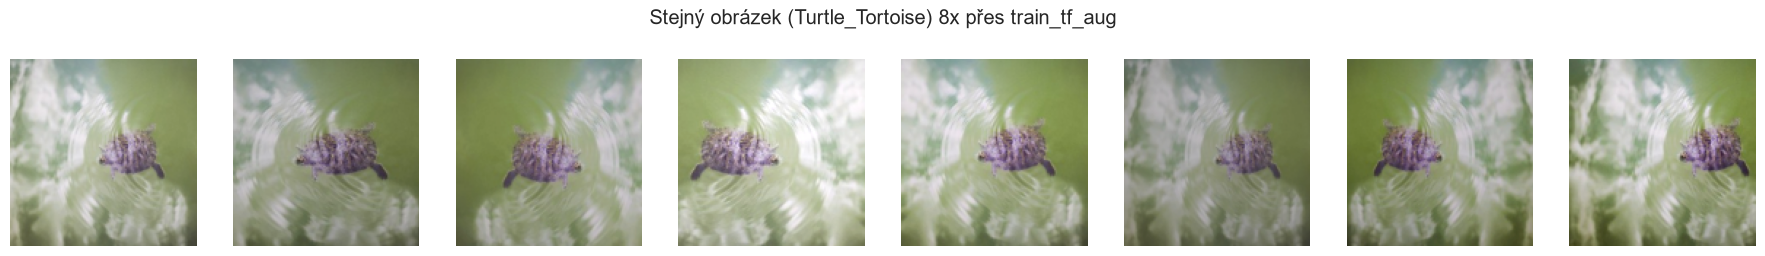

In [39]:
import copy

train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),           # náhodný výřez + zoom -> 128 x 128
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),  # bez hue
    transforms.ToTensor(),
    transforms.Normalize(MEAN.tolist(), STD.tolist()),
])

train_ds_aug = SeaAnimalsDataset(train_df, transform=train_tf_aug)
train_loader_aug = DataLoader(train_ds_aug, shuffle=True, **loader_kwargs)   # stejné nastavení jako v Části 1

# Ukázka: jeden obrázek 8x prošlý novou augmentací
fig, axes = plt.subplots(1, 8, figsize=(18, 2.6))
for ax in axes:
    img, lbl = train_ds_aug[0]
    ax.imshow(denormalize(img).permute(1, 2, 0)); ax.axis("off")
fig.suptitle(f"Stejný obrázek ({idx_to_class[lbl.item()]}) 8x přes train_tf_aug")
plt.tight_layout(); plt.show()

## 🏗️ Architektura `ImprovedCNN`

Základní stavební kámen je **blok** `conv_block`: 2× (Conv 3 × 3 → BatchNorm → ReLU) a na konci MaxPool.

| Část | Tvar výstupu |
|---|---|
| vstup | `(B, 3, 128, 128)` |
| blok 1 (3 → 32) | `(B, 32, 64, 64)` |
| blok 2 (32 → 64) | `(B, 64, 32, 32)` |
| blok 3 (64 → 128) | `(B, 128, 16, 16)` |
| blok 4 (128 → 256) | `(B, 256, 8, 8)` |
| `AdaptiveAvgPool2d(1)` = Global Average Pooling | `(B, 256, 1, 1)` |
| `Flatten` → `Dropout(0.3)` → `Linear(256 → 23)` | `(B, 23)` |

**Proč tato rozhodnutí:**
- **2 konvoluce v bloku** (styl sítě VGG) — dvě konvoluce 3 × 3 za sebou „vidí“ oblast 5 × 5 a mají mezi sebou
  ReLU navíc ⇒ síť může vytvořit složitější vzory, než kdyby rovnou zmenšovala.
- **4 bloky, kanály 32 → 256** — stejné pravidlo jako u baseline (poloviční rozlišení ⇒ dvojnásobek kanálů),
  jen o úroveň hlouběji. Receptivní pole na konci pokryje velkou část obrázku.
- **BatchNorm** — po každé konvoluci přepočítá výstupy na průměr ≈ 0 a rozptyl ≈ 1 (v rámci batche).
  Každá další vrstva tak dostává vstupy v podobném rozsahu ⇒ učení je stabilnější a rychlejší.
  Protože BatchNorm má vlastní posun (β), konvoluce před ním **nepotřebuje bias** (`bias=False`).
- **Global Average Pooling** — z každé z 256 map 8 × 8 vezme **průměr** ⇒ 256 čísel = „jak moc je v obrázku
  přítomen vzor č. *k*“. Poslední vrstva má pak jen 256 · 23 + 23 = **5 911 vah** místo 377 tisíc u baseline.
  Bonus: síť funguje pro libovolnou velikost vstupu.
- **Dropout(0.3)** — při tréninku náhodně vynuluje 30 % z 256 čísel ⇒ klasifikátor se nemůže spoléhat
  na jeden konkrétní vzor. Při `model.eval()` se vypne (tady už `model.train()` / `model.eval()` z Části 3
  **opravdu něco dělají** — přepínají Dropout i BatchNorm).

In [40]:
def conv_block(c_in, c_out):
    # 2x (Conv 3x3 -> BatchNorm -> ReLU) a MaxPool: (B, c_in, H, W) -> (B, c_out, H/2, W/2)
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),   # bias nahradí BatchNorm
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class ImprovedCNN(nn.Module):
    def __init__(self, n_classes, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),        # -> (B, 32, 64, 64)
            conv_block(32, 64),       # -> (B, 64, 32, 32)
            conv_block(64, 128),      # -> (B, 128, 16, 16)
            conv_block(128, 256),     # -> (B, 256, 8, 8)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # Global Average Pooling -> (B, 256, 1, 1)
            nn.Flatten(),             # -> (B, 256)
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),  # -> (B, 23) logity
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(SEED)
model2 = ImprovedCNN(n_classes=N_CLASSES).to(device)

n_params2 = sum(p.numel() for p in model2.parameters())
n_fc2 = sum(p.numel() for p in model2.classifier.parameters())
print(f"Parametrů: {n_params2:,} (baseline {n_params:,}) | z toho poslední vrstva {n_fc2:,} ({n_fc2 / n_params2:.1%})")

# Kontrola tvarů na skutečném batchi z Části 1
model2.eval()
with torch.no_grad():
    h = images.to(device)
    print(f"{'vstup':<22} {tuple(h.shape)}")
    for i, block in enumerate(model2.features, start=1):
        h = block(h)
        print(f"{'blok ' + str(i):<22} {tuple(h.shape)}")
    for layer in model2.classifier:
        h = layer(h)
        print(f"{layer.__class__.__name__:<22} {tuple(h.shape)}")
assert h.shape == (images.shape[0], N_CLASSES)
print("✅ Výstup", tuple(h.shape), "= (batch, počet tříd)")

Parametrů: 1,179,127 (baseline 400,439) | z toho poslední vrstva 5,911 (0.5%)
vstup                  (64, 3, 128, 128)
blok 1                 (64, 32, 64, 64)
blok 2                 (64, 64, 32, 32)
blok 3                 (64, 128, 16, 16)
blok 4                 (64, 256, 8, 8)
AdaptiveAvgPool2d      (64, 256, 1, 1)
Flatten                (64, 256)
Dropout                (64, 256)
Linear                 (64, 23)
✅ Výstup (64, 23) = (batch, počet tříd)


> 💡 Vylepšený model má **víc parametrů** (~1,2 mil. vs. 0,4 mil.), a přesto by se měl přeučovat **méně**:
> parametry jsou v konvolucích, které sdílí filtry po celém obrázku a učí se obecné vzory, ne v jedné obří
> lineární vrstvě, která si snadno zapamatuje konkrétní trénovací obrázky.

## ⚙️ Nastavení tréninku

| Volba | Hodnota | Proč |
|---|---|---|
| Optimizer | `AdamW`, lr = 1e-3, `weight_decay = 0.01` | AdamW = Adam se správně odděleným **weight decay**: v každém kroku váhy mírně zmenší ⇒ síť dává přednost jednodušším řešením (regularizace). 0,01 je výchozí hodnota AdamW |
| Plánovač lr | `CosineAnnealingLR` přes 30 epoch | learning rate plynule klesá z 1e-3 k ~0 po křivce kosinu: na začátku velké kroky (rychlý pokrok), na konci malé (jemné doladění) |
| Epochy | 30 | augmentace a regularizace zpomalují učení ⇒ model potřebuje víc epoch |
| Výběr modelu | nejlepší epocha podle **val accuracy** | uložíme kopii vah (`state_dict`) vždy, když se val accuracy zlepší |
| Loss pro trénink | `CrossEntropyLoss(weight=váhy_tříd)` | **řešení nevyváženosti**: váha třídy = `počet_vzorků / (počet_tříd · počet_vzorků_třídy)` ⇒ vzácná třída má váhu > 1, častá < 1 |
| Loss pro validaci | obyčejná `CrossEntropyLoss` (`criterion` z Části 3) | aby šla validační loss **přímo porovnat s baseline** |

> 💡 **Train accuracy teď bude nižší než validační** — to není chyba. Trénovací obrázky jsou augmentované
> (těžší) a při tréninku je zapnutý Dropout. Validace vidí čisté obrázky a Dropout je vypnutý.

In [41]:
EPOCHS2 = 30

# Váhy tříd z TRÉNOVACÍ sady: N / (K * n_c)
train_counts = torch.bincount(torch.tensor(train_df["label_idx"].values), minlength=N_CLASSES)
class_weights = train_counts.sum() / (N_CLASSES * train_counts.float())
for name in ["Turtle_Tortoise", "Jelly Fish", "Fish", "Seal"]:
    i = class_to_idx[name]
    print(f"{name:<16} {train_counts[i].item():5d} obr. -> váha {class_weights[i]:.2f}")

criterion_w = nn.CrossEntropyLoss(weight=class_weights.to(device))   # jen pro trénink

torch.manual_seed(SEED)
model2 = ImprovedCNN(n_classes=N_CLASSES).to(device)                # čerstvé váhy (buňka jde spustit znovu)
optimizer2 = torch.optim.AdamW(model2.parameters(), lr=1e-3, weight_decay=0.01)
scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=EPOCHS2)

Turtle_Tortoise   1331 obr. -> váha 0.31
Jelly Fish         591 obr. -> váha 0.70
Fish               346 obr. -> váha 1.20
Seal               288 obr. -> váha 1.44


## 🏋️ Trénink vylepšeného modelu

Použijeme **stejné funkce `train_one_epoch` a `evaluate` z Části 3** — jen s jiným modelem, DataLoaderem,
loss a optimizerem. Navíc po každé epoše:
- `scheduler2.step()` — sníží learning rate podle kosinové křivky,
- pokud je val accuracy nejlepší dosud, uložíme **kopii vah** (`copy.deepcopy(model2.state_dict())`;
  bez `deepcopy` bychom měli jen odkaz na váhy, které se dalším tréninkem mění) — označeno ⭐.

Po tréninku do modelu **načteme nejlepší váhy**.

In [42]:
history2 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
best_acc2, best_epoch2, best_state2 = 0.0, 0, None

t_start = time.perf_counter()
for epoch in range(1, EPOCHS2 + 1):
    t0 = time.perf_counter()
    lr_now = scheduler2.get_last_lr()[0]
    train_loss, train_acc = train_one_epoch(model2, train_loader_aug, criterion_w, optimizer2)
    val_loss, val_acc     = evaluate(model2, val_loader, criterion)
    scheduler2.step()

    for key, val in zip(history2, [train_loss, train_acc, val_loss, val_acc, lr_now]):
        history2[key].append(val)

    star = ""
    if val_acc > best_acc2:
        best_acc2, best_epoch2 = val_acc, epoch
        best_state2 = copy.deepcopy(model2.state_dict())
        star = " ⭐"
    print(f"epocha {epoch:2d}/{EPOCHS2} | lr {lr_now:.1e} | train loss {train_loss:.3f}, acc {train_acc:6.1%} "
          f"| val loss {val_loss:.3f}, acc {val_acc:6.1%} | {time.perf_counter() - t0:4.1f} s{star}")

print(f"\nCelkový čas tréninku: {(time.perf_counter() - t_start) / 60:.1f} min")
model2.load_state_dict(best_state2)
print(f"Načteny váhy z nejlepší epochy {best_epoch2}: val accuracy {best_acc2:.1%} (baseline {max(history['val_acc']):.1%})")

epocha  1/30 | lr 1.0e-03 | train loss 2.701, acc  17.3% | val loss 2.526, acc  19.9% | 25.7 s ⭐


epocha  2/30 | lr 1.0e-03 | train loss 2.514, acc  22.8% | val loss 2.453, acc  26.3% | 13.9 s ⭐


epocha  3/30 | lr 9.9e-04 | train loss 2.406, acc  26.3% | val loss 2.462, acc  24.4% | 13.7 s


epocha  4/30 | lr 9.8e-04 | train loss 2.326, acc  29.4% | val loss 2.442, acc  26.2% | 13.9 s


epocha  5/30 | lr 9.6e-04 | train loss 2.279, acc  30.7% | val loss 2.444, acc  24.9% | 14.0 s


...

epocha 26/30 | lr 6.7e-05 | train loss 1.410, acc  57.8% | val loss 1.515, acc  54.0% | 14.1 s ⭐


epocha 27/30 | lr 4.3e-05 | train loss 1.388, acc  59.4% | val loss 1.502, acc  54.0% | 14.1 s


epocha 28/30 | lr 2.4e-05 | train loss 1.381, acc  59.2% | val loss 1.502, acc  54.2% | 13.4 s ⭐


epocha 29/30 | lr 1.1e-05 | train loss 1.381, acc  59.4% | val loss 1.510, acc  54.6% | 13.5 s ⭐


epocha 30/30 | lr 2.7e-06 | train loss 1.365, acc  59.9% | val loss 1.488, acc  55.1% | 14.0 s ⭐

Celkový čas tréninku: 7.1 min
Načteny váhy z nejlepší epochy 30: val accuracy 55.1% (baseline 42.9%)


## 📈 Křivky učení: baseline vs. vylepšený model

Validační křivky baseline (z Části 3) jsou kresleny **čárkovaně** pro přímé srovnání.
Hvězdička označuje epochu, jejíž váhy jsme si ponechali.

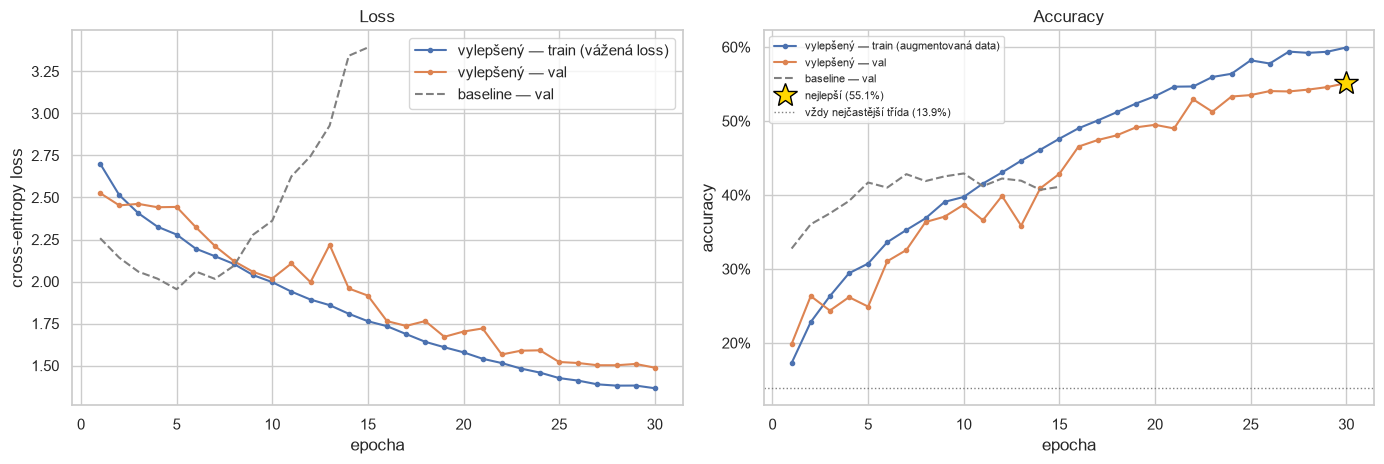

In [43]:
ep1 = range(1, EPOCHS + 1)
ep2 = range(1, EPOCHS2 + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(ep2, history2["train_loss"], "o-", ms=3, label="vylepšený — train (vážená loss)")
axes[0].plot(ep2, history2["val_loss"],   "o-", ms=3, label="vylepšený — val")
axes[0].plot(ep1, history["val_loss"], "--", color="gray", label="baseline — val")
axes[0].set_xlabel("epocha"); axes[0].set_ylabel("cross-entropy loss"); axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(ep2, history2["train_acc"], "o-", ms=3, label="vylepšený — train (augmentovaná data)")
axes[1].plot(ep2, history2["val_acc"],   "o-", ms=3, label="vylepšený — val")
axes[1].plot(ep1, history["val_acc"], "--", color="gray", label="baseline — val")
axes[1].plot(best_epoch2, best_acc2, "*", color="gold", ms=18, markeredgecolor="black", label=f"nejlepší ({best_acc2:.1%})")
axes[1].axhline(majority_acc, color="gray", ls=":", lw=1, label=f"vždy nejčastější třída ({majority_acc:.1%})")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_xlabel("epocha"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

## ⚖️ Srovnání po třídách a vliv nevyváženosti

Dvě otázky:
1. **Zlepšil se model u všech tříd, nebo jen u některých?** — accuracy po třídách, baseline vs. vylepšený.
2. **„Nadržuje“ model velkým třídám?** — porovnáme, **kolikrát model danou třídu predikoval** s tím,
   kolikrát ve validaci **skutečně je**. Poměr > 1 = model ji tipuje příliš často (např. „když nevím, řeknu želva“),
   poměr < 1 = příliš zřídka. Ideál je 1.

Baseline predikce bereme z Části 3 (`preds` — model po 15. epoše).

              accuracy  macro acc
baseline         41.1%      37.4%
vylepšený        55.1%      52.4%


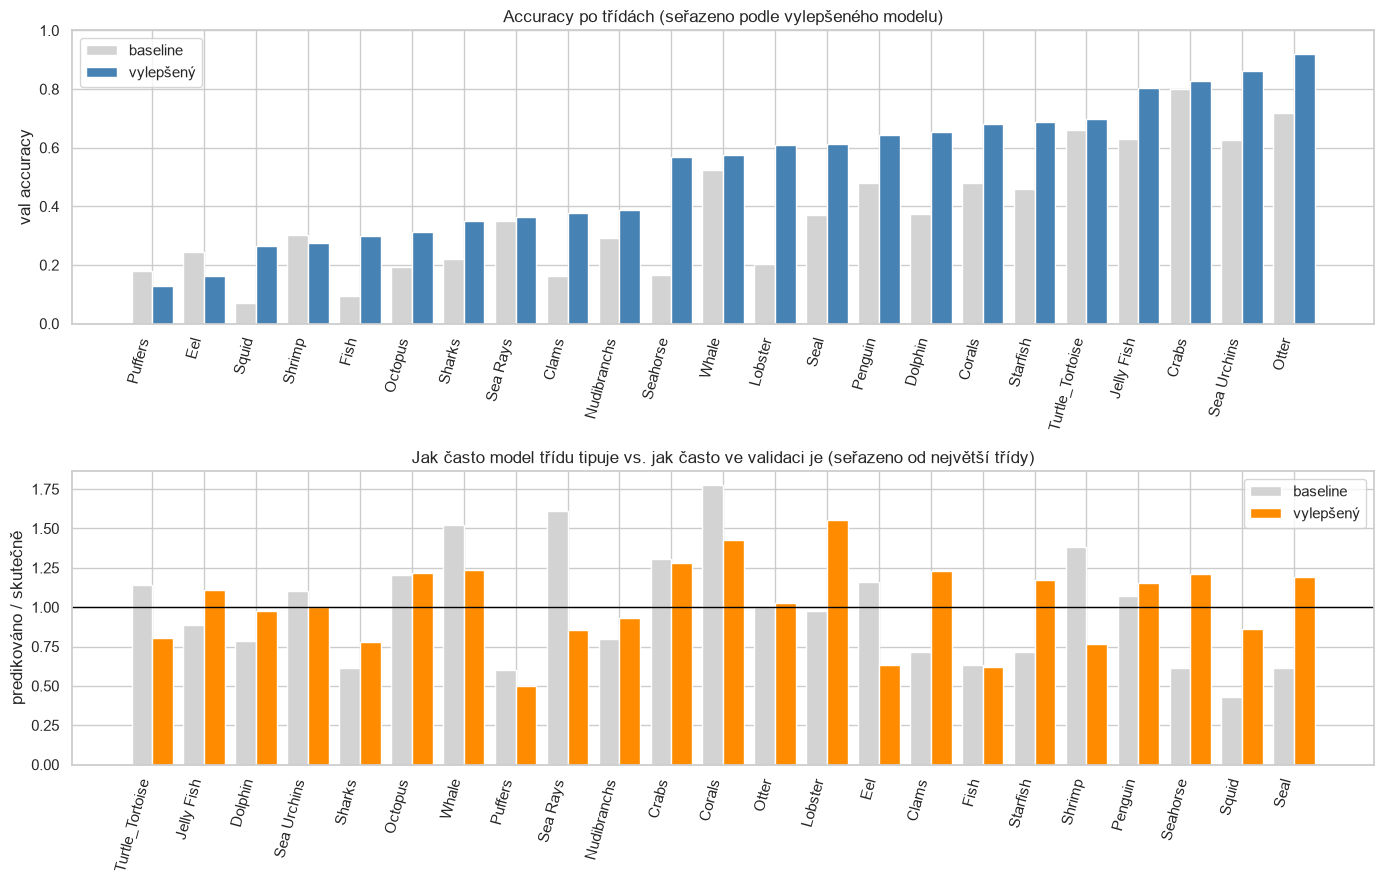

Turtle_Tortoise: tipováno 1.14x (baseline) vs. 0.80x (vylepšený) oproti skutečnosti
Seal:            tipováno 0.61x (baseline) vs. 1.19x (vylepšený); accuracy 37% -> 61%


In [44]:
base_preds = preds.clone()                                        # baseline z Části 3

model2.eval()
imp_list = []
with torch.no_grad():
    for x, _ in val_loader:
        imp_list.append(model2(x.to(device)).argmax(dim=1).cpu())
imp_preds = torch.cat(imp_list)

def per_class_acc(p):
    correct = torch.bincount(labels_val[p == labels_val], minlength=N_CLASSES)
    return (correct / total_per_class).numpy()

acc_base, acc_imp = per_class_acc(base_preds), per_class_acc(imp_preds)
print(f"{'':<12} {'accuracy':>9} {'macro acc':>10}")
print(f"{'baseline':<12} {(base_preds == labels_val).float().mean():9.1%} {acc_base.mean():10.1%}")
print(f"{'vylepšený':<12} {(imp_preds == labels_val).float().mean():9.1%} {acc_imp.mean():10.1%}")

order = np.argsort(acc_imp)
xpos = np.arange(N_CLASSES)
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].bar(xpos - 0.2, acc_base[order], width=0.4, color="lightgray", label="baseline")
axes[0].bar(xpos + 0.2, acc_imp[order],  width=0.4, color="steelblue", label="vylepšený")
axes[0].set_xticks(xpos, [idx_to_class[i] for i in order], rotation=75, ha="right")
axes[0].set_ylim(0, 1); axes[0].set_ylabel("val accuracy"); axes[0].legend()
axes[0].set_title("Accuracy po třídách (seřazeno podle vylepšeného modelu)")

true_counts = total_per_class.float()
ratio_base = torch.bincount(base_preds, minlength=N_CLASSES) / true_counts
ratio_imp  = torch.bincount(imp_preds,  minlength=N_CLASSES) / true_counts
size_order = np.argsort(-true_counts.numpy())                      # od největší třídy
axes[1].bar(xpos - 0.2, ratio_base[size_order], width=0.4, color="lightgray", label="baseline")
axes[1].bar(xpos + 0.2, ratio_imp[size_order],  width=0.4, color="darkorange", label="vylepšený")
axes[1].axhline(1, color="black", lw=1)
axes[1].set_xticks(xpos, [idx_to_class[i] for i in size_order], rotation=75, ha="right")
axes[1].set_ylabel("predikováno / skutečně"); axes[1].legend()
axes[1].set_title("Jak často model třídu tipuje vs. jak často ve validaci je (seřazeno od největší třídy)")

plt.tight_layout(); plt.show()

t, s = class_to_idx["Turtle_Tortoise"], class_to_idx["Seal"]
print(f"Turtle_Tortoise: tipováno {ratio_base[t]:.2f}x (baseline) vs. {ratio_imp[t]:.2f}x (vylepšený) oproti skutečnosti")
print(f"Seal:            tipováno {ratio_base[s]:.2f}x (baseline) vs. {ratio_imp[s]:.2f}x (vylepšený); "
      f"accuracy {acc_base[s]:.0%} -> {acc_imp[s]:.0%}")

## 📝 Shrnutí Části 5

| | Baseline (Část 3) | Vylepšený model |
|---|---|---|
| Parametrů | 400 tis. (94 % v poslední vrstvě) | 1,18 mil. (0,5 % v poslední vrstvě) |
| Nejlepší val accuracy | 42,9 % | **55,1 %** (+12,2 p. b.) |
| Val macro accuracy | 37,4 % | **52,4 %** (+15,0 p. b.) |
| Nejnižší val loss | 1,95 | **1,49** |
| Čas tréninku | ~2 min (15 epoch) | ~7 min (30 epoch) |

- **Přeučení zmizelo.** U baseline val loss od 5. epochy rostla; u vylepšeného modelu **klesá až do poslední
  epochy** a train accuracy (60 %) je jen o ~5 p. b. nad validační (55 %). Train accuracy je tak nízko proto,
  že trénovací obrázky jsou augmentované a při tréninku je zapnutý Dropout — přesně to brání zapamatování.
- **Model ještě nedotrénoval:** nejlepší epocha je ta **poslední** a val accuracy stále roste ⇒ víc epoch
  by pravděpodobně přineslo další zlepšení. Kosinový plánovač ale na konci snížil lr téměř na nulu, takže
  růst se už zpomaluje.
- **Po třídách:** zlepšilo se **20 z 23 tříd**, nejvíc Seahorse a Lobster (o ~40 p. b.), Dolphin, Sea Urchins
  a Clams (o ~20–30 p. b.). Mírně se zhoršily jen Puffers, Eel a Shrimp. Nejtěžší zůstávají třídy, které se
  podobají jiným (Puffers / Fish, Eel, Squid / Octopus).
- **Nevyváženost tříd (váhy v loss):**
  - baseline **přetipovával** největší třídu Turtle_Tortoise (1,14× častěji, než ve validaci je) a malé třídy
    podtipovával (Seal jen 0,61×),
  - s váhami tříd se to obrátilo: Turtle 0,80×, Seal 1,19× a **accuracy tuleňů stoupla z 37 % na 61 %**,
  - váhy tedy mírně **překorigovaly** (malé třídy se teď tipují trochu častěji, než by měly) — ale macro accuracy,
    která dává všem třídám stejnou váhu, stoupla víc než celková accuracy (+15,0 vs. +14,0 p. b.).
- **Co pomohlo:** nejde to oddělit (měnili jsme vše najednou), ale z křivek je vidět, že rozhodující bylo
  **odstranění přeučení** — augmentace, Global Average Pooling místo obří lineární vrstvy, Dropout a weight decay.

> 💡 **Další možná zlepšení** (do dalších milestonů): delší trénink (50+ epoch), vyšší rozlišení (160–224 px),
> jemnější váhy tříd (např. odmocnina z poměru) a hlavně **transfer learning** z předtrénované sítě.

**Další krok (Část 6):** jednorázové vyhodnocení obou modelů na testovací sadě a celkové shrnutí.

# 🏁 Část 6 — Vyhodnocení na testu a celkové shrnutí

## 🧾 Testovací sada

Test set (2 040 obrázků) jsme **celou dobu nepoužili** — ani k ladění, ani k výběru epochy. Všechna rozhodnutí
(architektura, augmentace, výběr nejlepší epochy) padla podle **validační** sady. Proto je test
**nezávislý odhad**, jak modely fungují na úplně nových obrázcích.

Vyhodnotíme ho **jednou, pro oba modely najednou**, a podle výsledku už nic neměníme — jinak by se test stal
další validační sadou a jeho číslo by bylo příliš optimistické.

- **Baseline:** model po 15. (poslední) epoše z Části 3 — tak, jak byl natrénován.
- **Vylepšený:** váhy z nejlepší epochy podle validace (Část 5).
- Používáme stejnou funkci `evaluate` (`model.eval()` + `torch.no_grad()`) a nevážnou `criterion`.

In [45]:
def predict(model, loader):
    # Vrátí predikované třídy a skutečné labely pro celý loader
    model.eval()
    all_p, all_y = [], []
    with torch.no_grad():
        for x, y in loader:
            all_p.append(model(x.to(device)).argmax(dim=1).cpu())
            all_y.append(y)
    return torch.cat(all_p), torch.cat(all_y)


def macro_acc(p, y):
    correct = torch.bincount(y[p == y], minlength=N_CLASSES)
    total = torch.bincount(y, minlength=N_CLASSES)
    return (correct / total).mean().item()


results = {}
for name, m in [("baseline", model), ("vylepšený", model2)]:
    test_loss, test_acc = evaluate(m, test_loader, criterion)
    p, y = predict(m, test_loader)
    results[name] = {"loss": test_loss, "acc": test_acc, "macro": macro_acc(p, y)}

val_ref = {"baseline": (history["val_acc"][-1], acc_base.mean()),
           "vylepšený": (best_acc2, acc_imp.mean())}

print(f"{'model':<11} | {'val acc':>8} {'val macro':>10} | {'test loss':>9} {'test acc':>9} {'test macro':>11}")
print("-" * 70)
for name, r in results.items():
    va, vm = val_ref[name]
    print(f"{name:<11} | {va:8.1%} {vm:10.1%} | {r['loss']:9.3f} {r['acc']:9.1%} {r['macro']:11.1%}")
print(f"\nZlepšení na testu: accuracy +{(results['vylepšený']['acc'] - results['baseline']['acc']) * 100:.1f} p. b., "
      f"macro +{(results['vylepšený']['macro'] - results['baseline']['macro']) * 100:.1f} p. b.")

model       |  val acc  val macro | test loss  test acc  test macro
----------------------------------------------------------------------
baseline    |    41.1%      37.4% |     3.257     39.5%       35.9%
vylepšený   |    55.1%      52.4% |     1.427     56.6%       54.1%

Zlepšení na testu: accuracy +17.1 p. b., macro +18.2 p. b.


## 📝 Celkové shrnutí Milestone 1

### 🧾 Výsledky na testovací sadě (2 040 obrázků, 23 tříd)

| Model | Parametrů | Val accuracy | **Test accuracy** | **Test macro accuracy** | Test loss |
|---|---|---|---|---|---|
| vždy nejčastější třída | — | — | ~14 % | ~4 % | — |
| Baseline CNN (Části 2–3) | 0,40 mil. | 41,1 % | **39,5 %** | **35,9 %** | 3,26 |
| Vylepšená CNN (Část 5) | 1,18 mil. | 55,1 % | **56,6 %** | **54,1 %** | 1,43 |

- Testovací výsledky **odpovídají validačním** (rozdíl ~1–2 p. b.) ⇒ validační sada byla spolehlivým vodítkem a
  výběrem nejlepší epochy jsme se jí „nepřizpůsobili“.
- Vylepšený model je na testu o **+17,1 p. b.** (accuracy) a **+18,2 p. b.** (macro accuracy) lepší než baseline.
  Vysoká test loss baseline (3,26) odpovídá jeho přeučení — u chybných predikcí je příliš sebejistý.

### ✅ Splnění zadání

| Požadavek | Kde | Výsledek |
|---|---|---|
| Vlastní `Dataset` (`__len__`, `__getitem__`) | Část 1 | `SeaAnimalsDataset` — líné načítání, převod na RGB, label jako `torch.long` |
| `DataLoader` (batch, shuffle, `num_workers`) | Část 1 | batch 64, shuffle jen u train, 4 workery + `persistent_workers` (změřeno ~1,9× rychlejší než 0 workerů) |
| Vizualizace batche se správnými tvary | Část 1 | `(64, 3, 128, 128)` float32, labely `(64,)` int64, ověřeno asserty |
| Baseline `nn.Module` od nuly, bez předtrénovaných vah | Část 2 | 3× Conv-ReLU-MaxPool + Linear, vstup 3 × 128 × 128, výstup 23 logitů |
| Ruční train smyčka (`zero_grad`, `backward`, `step`) | Část 3 | `train_one_epoch` |
| Oddělená validace (`model.eval()`, `torch.no_grad()`) | Část 3 | `evaluate` |
| Ruční akumulace metrik přes batche | Část 3 | loss a accuracy vážené velikostí batche |
| Overfit sanity check (8–16 vzorků) | Část 4 | 16 obrázků: loss 3,1 → 1,5·10⁻⁸, 100 % accuracy od 4. epochy, křivka + tabulka |

### 🔑 Hlavní zjištění

1. **Pipeline je bez chyb.** Overfit check prokázal, že gradienty tečou správně, labely odpovídají predikcím
   a v pipeline nejsou tiché broadcasting bugy. Kontrola loss s náhodnými vahami (≈ ln 23) to potvrdila už před tréninkem.
2. **Baseline (neasistovaný výkon): ~40 %** — ~3× lepší než naivní odhad, ale se silným **přeučením**
   (train 91 % vs. val 41 %, val loss od 5. epochy roste).
3. **Vylepšená síť od nuly: ~56 %.** Rozhodující bylo **omezit přeučení** (silnější augmentace, Global Average
   Pooling místo obří lineární vrstvy, Dropout, weight decay) a stabilnější učení (BatchNorm, kosinový plánovač lr).
4. **Nevyváženost tříd** (Turtle 4,6× víc než Seal) model ovlivňovala — baseline želvy přetipovával a tuleně
   podtipovával. Váhy tříd v loss to vyrovnaly (accuracy tuleňů 37 % → 61 %), mírně ale překorigovaly.
5. **Nejtěžší jsou vizuálně podobné třídy** (Fish / Puffers, Squid / Octopus, Eel), ne nejmenší třídy —
   podobnost tříd rozhoduje víc než počet obrázků.
6. **Reprodukovatelnost:** pevný seed + deterministické cuDNN ⇒ „Run All“ dává pokaždé stejná čísla.

### ➡️ Další kroky (další milestony)
- **Transfer learning** z předtrénované sítě (např. ResNet) — u ~9,5 tisíce trénovacích obrázků obvykle největší skok.
- Delší trénink (vylepšený model se ve 30. epoše ještě zlepšoval), vyšší rozlišení, jemnější vyvážení tříd.
- Analýza chyb pomocí **confusion matrix** — které dvojice tříd si model plete.